# Parkinson's Disease Detection from T1-Weighted MRI with Radiomics and Random Forests

This notebook builds a classical machine-learning pipeline that separates **Parkinson's disease (PD)** patients from **healthy controls** using 3D T1-weighted brain MRI.

Each scan is registered to a standard PD-specific brain atlas. Radiomic texture and intensity features are then extracted from the atlas's subcortical structures, which are the regions most affected by PD, and used to train scikit-learn classifiers.

| | |
|---|---|
| **PD scans** | [Parkinson's Progression Markers Initiative (PPMI)](https://www.ppmi-info.org/), T1-weighted MPRAGE |
| **Healthy scans** | [IXI dataset](https://brain-development.org/ixi-dataset/), T1-weighted |
| **Pre-processing** | DICOM → NIfTI (`dcm2niix`), non-linear registration to the MNI PD25 atlas (ANTsPy, SyN) |
| **Features** | PyRadiomics features from a binary mask of the eight PD25 subcortical structures |
| **Models** | Random Forest (with and without SVM-based feature selection) and Gaussian Naive Bayes |

**Notebook outline:** Unzipping Dataset → DICOM to NIfTI Conversion → Registration → Feature Extraction → Combining CSVs → Data Exploration → Train/Test Split → Model Training and Evaluation (base model, Naive Bayes, model with feature selection) → Saving models → ROI plots.

> **Note on running this notebook.** This is the original course-project notebook, kept as it was; only these explanatory cells have been added. It ran on Google Colab with data on Google Drive (`/content/drive/MyDrive/ML_proj/...`). The heavy steps (conversion, registration, feature extraction) were run in batches across several sessions, and some cells depend on files or variables created outside the notebook, so read it as a record of the experiments. It won't run top to bottom as-is. PPMI data is only available through the PPMI data-use agreement and isn't distributed with this project.

Extracts the downloaded DICOM archives (`PD_ML*.zip`, stored on Google Drive) into `/content/Dicoms`. The `!wget` cell has no URL. The scans were downloaded manually beforehand, because PPMI data requires registration and approval.

# Unzipping Dataset

In [ ]:
!wget

In [ ]:
import zipfile
import os

In [ ]:
path = '/content/drive/MyDrive/ML_proj/Zip_files'
out = '/content/Dicoms'
for i in os.listdir(path):
  print(i)
  path1 = os.path.join(path, i)
  with zipfile.ZipFile(path1, 'r') as zip_ref:
    zip_ref.extractall(out)
print('completed')

PD_ML.zip
PD_ML1.zip
PD_ML_dataset.zip
PD_ML2.zip
PD_ML3.zip
completed


# Dicom to Nifti Conversion

Installs **dcm2niix**, the standard DICOM-to-NIfTI converter, along with `pigz` (parallel gzip), which dcm2niix uses to write compressed `.nii.gz` files.

In [ ]:
!pip install pigz-python
!sudo apt-get install dcm2niix

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libyaml-cpp0.7 pigz
The following NEW packages will be installed:
  dcm2niix libyaml-cpp0.7 pigz
0 upgraded, 3 newly installed, 0 to remove and 8 not upgraded.
Need to get 417 kB of archives.
After this operation, 1,393 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 pigz amd64 2.6-1 [63.6 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/main amd64 libyaml-cpp0.7 amd64 0.7.0+dfsg-8build1 [97.7 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 dcm2niix amd64 1.0.20211006-1build1 [256 kB]
Fetched 417 kB in 0s (1,437 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 3.)
debconf: falling back to frontend: Readl

Walks the nested PPMI download layout (`subject / sequence / date / image ID / *.dcm`) and converts each DICOM series to one compressed NIfTI volume named `<subject>_<imageID>.nii.gz`. Volumes that already exist are skipped, so the cell can be resumed after a Colab timeout.

dcm2niix flags: `-z y` compresses the output, `-i y` ignores derived/localiser images, and `-b y` writes a BIDS JSON sidecar.

In [ ]:
import os

root_dir = os.path.join(out)

# Set the path to the output directory where the NIfTI files will be saved
output_dir = '/content/drive/MyDrive/ML_proj/Nifti'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Loop over the subfolders in the root directory
for subfolderA in os.listdir(root_dir):
    subfolderA_path = os.path.join(root_dir, subfolderA)
    for subfolder1 in os.listdir(subfolderA_path):
        subfolder1_path = os.path.join(subfolderA_path, subfolder1)
        if os.path.isdir(subfolder1_path):
            print(f'{subfolder1} under process')
            # Check if subfolder1 already exists in output_dir
            # Loop over the nested folders in subfolder1
            for subfolder2 in os.listdir(subfolder1_path):
                #print(subfolder1)
                subfolder2_path = os.path.join(subfolder1_path, subfolder2)
                if os.path.isdir(subfolder2_path):
                    # Loop over the nested folders in subfolder2
                    for subfolder3 in os.listdir(subfolder2_path):
                        subfolder3_path = os.path.join(subfolder2_path, subfolder3)
                        dti_files = []
                        out_path = os.path.join(output_dir, f'{subfolder1}.nii.gz')
                        if os.path.isdir(subfolder3_path):
                            # Loop over the nested folders in subfolder3
                            for subfolder4 in os.listdir(subfolder3_path):
                              if os.path.exists(os.path.join(output_dir, f'{subfolder1}_{subfolder4}.nii.gz')):
                                print(f'{subfolder1}_{subfolder4}.nii.gz already exist, skipping')
                                continue

                              subfolder4_path = os.path.join(subfolder3_path, subfolder4)
                              if os.path.isdir(subfolder4_path):
                                print(f'{subfolder1}_{subfolder4} under process')
                              out_p = os.path.join(output_dir, f"{subfolder1}_{subfolder4}.nii.gz")

                              !dcm2niix -o {output_dir} -z y -i y -f {subfolder1+'_'+subfolder4} -b y {subfolder4_path}


Streaming output truncated to the last 5000 lines.
Convert 176 DICOM as /content/drive/MyDrive/ML_proj/Nifti/52678_I581174 (240x256x176x1)
Compress: "/usr/bin/pigz" -b 960 -n -f -6 "/content/drive/MyDrive/ML_proj/Nifti/52678_I581174.nii"
Conversion required 2.678214 seconds (0.297017 for core code).
52678_I966930 under process
Chris Rorden's dcm2niiX version v1.0.20211006  (JP2:OpenJPEG) GCC11.2.0 x86-64 (64-bit Linux)
Found 176 DICOM file(s)
Convert 176 DICOM as /content/drive/MyDrive/ML_proj/Nifti/52678_I966930 (240x256x176x1)
Compress: "/usr/bin/pigz" -b 960 -n -f -6 "/content/drive/MyDrive/ML_proj/Nifti/52678_I966930.nii"
Conversion required 2.628437 seconds (0.322776 for core code).
52678_I1350997 under process
Chris Rorden's dcm2niiX version v1.0.20211006  (JP2:OpenJPEG) GCC11.2.0 x86-64 (64-bit Linux)
Found 176 DICOM file(s)
Convert 176 DICOM as /content/drive/MyDrive/ML_proj/Nifti/52678_I1350997 (240x256x176x1)
Compress: "/usr/bin/pigz" -b 960 -n -f -6 "/content/drive/MyDrive/M

Counts the converted volumes. 1,467 NIfTI files were produced.

In [ ]:
nif = 0
for i in os.listdir('/content/drive/MyDrive/ML_proj/Nifti'):
  if i.endswith('.nii.gz'):
    nif +=1
print(nif)

1467


# Registration

Scans from different scanners and sites sit in different coordinate spaces. To compare them voxel by voxel and apply one atlas-defined region of interest to every subject, each scan is registered to the **MNI PD25 T1 MPRAGE template (1 mm)**, a population-averaged atlas built specifically for Parkinson's disease. Registration uses **ANTsPy**, the Python wrapper for ANTs.

In [ ]:
!pip install antspyx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.9/345.9 MB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.5 MB/s eta 0:00:00


In [ ]:
import  ants
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import os
from natsort import natsorted

Sets the reference template, the input folder of NIfTI volumes and the output folder for registered scans.

In [ ]:
ref_path = '/content/drive/MyDrive/ML_proj/MNUPD25/PD25-T1MPRAGE-template-1mm.nii.gz'
path = '/content/drive/MyDrive/ML_proj/Nifti'
out = '/content/drive/MyDrive/ML_proj/Registered/PD'
if not os.path.exists(out):
  os.makedirs(out)


Registers each volume to the PD25 template with ANTs **SyN** (symmetric normalisation: an affine step followed by a deformable warp) and saves the warped image. The `[800:1100]` slice shows the volumes were processed in chunks across sessions, and existing outputs are skipped.

The output here goes to `Registered/PD`. The feature-extraction step below reads the healthy scans from `Registered/Healthy`, so this cell was presumably re-run with the paths changed for the IXI scans.

> Note: the IXI download and any IXI-specific preparation aren't part of this notebook. The ROI plot at the end refers to a Drive folder called `IXI_brain/`.

In [ ]:
count = 0
ref_img = ants.image_read(ref_path)
for h, i in enumerate(natsorted(os.listdir(path))[800:1100]):
    # Check if the file has a '.nii.gz' extension
    if i.endswith('.nii.gz'):
        # Check if the file already exists in the output directory `out`
        if os.path.exists(os.path.join(out, i)):
            print(f'{i} already exists, skipping')
            count += 1
            continue

        # Construct the image file path
        img_path = os.path.join(path, i)

        # Load the NIfTI image
        data = ants.image_read(img_path)
        registered = ants.registration(ref_img, data, type_of_transform='SyN')['warpedmovout']

        # define output path and filename
        out_file = os.path.join(out, i)
        print('Saving nifti image')
        registered.to_filename(out_file)
        count += 1
        del registered, data
    else:
      continue
print('Subjects Processed:', count)

# Features Etraction

### Radiomic feature extraction

Installs **PyRadiomics**, which computes quantitative image features (first-order intensity statistics, shape and texture matrices) inside a mask.

In [ ]:
!pip install pyradiomics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.5/34.5 MB 30.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Discarding https://files.pythonhosted.org/packages/03/c1/20fc2c50ab1e3304da36d866042a1905a2b05a1431ece35448ab6b4578f2/pyradiomics-3.1.0.tar.gz (from https://pypi.org/simple/pyradiomics/): Requested pyradiomics from https://files.pythonhosted.org/packages/03/c1/20fc2c50ab1e3304da36d866042a1905a2b05a1431ece35448ab6b4578f2/pyradiomics-3.1.0.tar.gz has inconsistent version: expected '3.1.0', but metadata has '3.0.1a1'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.5/34.5 MB 10.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 MB 9.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.4/116.4 kB 17.9 MB/s eta 0:00:

In [ ]:
import os
#import pyradiomics
import nibabel as nib
import numpy as np
from natsort import natsorted

Defines the input folder (registered healthy scans), the output folder for per-subject feature CSVs, and the binary subcortical mask built from the PD25 atlas (see the mask cells below).

In [ ]:
path = '/content/drive/MyDrive/ML_proj/Registered/Healthy'
out = '/content/drive/MyDrive/ML_proj/Features2/Healthy'
if not os.path.exists(out):
      os.makedirs(out)
Mask = '/content/drive/MyDrive/ML_proj/MNUPD25/PD25-subcortical-1mm_bmask.nii.gz'

Runs the PyRadiomics command-line tool with default settings on each registered scan, using the subcortical mask, and writes one CSV per subject. The cell shown here processes the **Healthy** class. The PD class was handled the same way into `Features2/PD`, since both sub-folders are combined later. The output folder holds 496 healthy feature files.

In [ ]:
count = 0
for i in natsorted(os.listdir(path)):
  if count<510:
    print(i)
    if i.endswith('.nii.gz'):
      file_name = i.split('.nii.gz')[0]
      if os.path.exists(os.path.join(out, file_name+'.csv')):
            print(f'{file_name}.csv already exists, skipping')
            count += 1
            continue
      img_path = os.path.join(path, i)
      #image_path = eval(img_path)
      # print(i.split('.nii.gz')[0])
      #print(h)

      out_file = os.path.join(out, file_name+'.csv') # , i.split('.nii.gz')[i]
      #image = sitk.ReadImage(img_path)
      !pyradiomics {img_path} {Mask} -o {out_file} -f csv
      count+=1
  else:
    break
print(f"Features extracted for {count} subjects")

002-Guys-0828-T1.nii.gz
[2023-12-28 07:38:16] W: radiomics.glcm: GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
012-HH-1211-T1.nii.gz
[2023-12-28 07:38:22] W: radiomics.glcm: GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
013-HH-1212-T1.nii.gz
[2023-12-28 07:38:29] W: radiomics.glcm: GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
014-HH-1236-T1.nii.gz
[2023-12-28 07:38:36] W: radiomics.glcm: GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
015-HH-1258-T1.nii.gz
[2023-12-28 07:38:44] W: radiomics.glcm: GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
016-Guys-0697-T1.nii.gz
[2023-12-28 07:38:47] W: radiomics.glcm: GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
017-Guys-0698-T1.nii.gz
[2023-12-28 07:38:51] W: radio

In [ ]:
len(os.listdir(out))

496

### Binary region-of-interest mask

The PD25 subcortical atlas labels eight structures with distinct integer values: caudate nucleus, putamen, globus pallidus internus and externus, thalamus, subthalamic nucleus, substantia nigra and red nucleus. The cells below load this label map (193 × 229 × 193 voxels), merge all structures into one binary mask (`mask > 0`), plot it and save it as `PD25-subcortical-1mm_bmask.nii.gz`. The web app (`app/`) uses this same file.

> The mask file is referenced by the feature-extraction cell above, so these cells were run before it, even though they appear later in the notebook.

In [ ]:
masked = nib.load(Mask)
masked.shape

(193, 229, 193)

In [ ]:
len(os.listdir('/content/drive/MyDrive/ML_proj/Registered/Healthy'))

496

In [ ]:
mask = masked.get_fdata()

In [ ]:
!pip install -U nilearn
from nilearn import plotting

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 29.8 MB/s eta 0:00:00


In [ ]:
binary_mask_data = np.where(mask > 0, 1, 0)
binary_mask = nib.Nifti1Image(binary_mask_data, masked.affine, masked.header)



/usr/local/lib/python3.10/dist-packages/nilearn/plotting/img_plotting.py:407: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  anat_img = new_img_like(anat_img, data, affine=anat_img.affine)


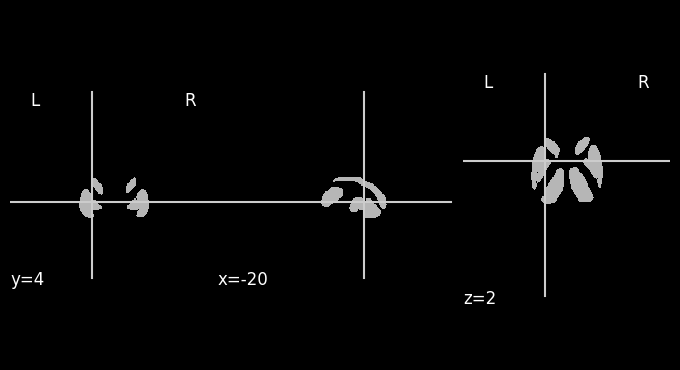

In [ ]:
plotting.plot_anat(binary_mask, cut_coords=(-20, 4, 2))

In [ ]:
binary_mask.to_filename('/content/drive/MyDrive/ML_proj/MNUPD25/PD25-subcortical-1mm_bmask.nii.gz')

Plots the original multi-label subcortical atlas for comparison with the binary mask.

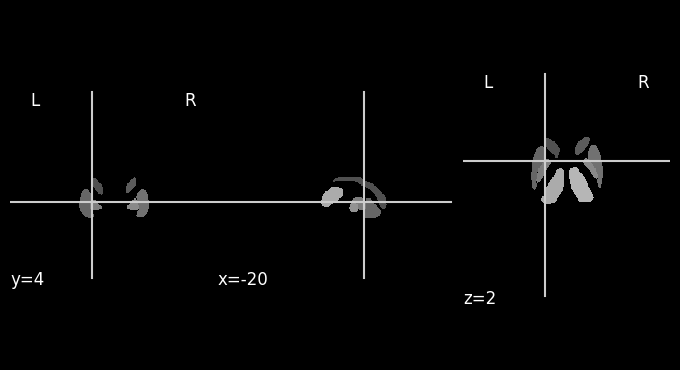

In [ ]:
plotting.plot_anat(masked, cut_coords=(-20, 4, 2))

# Combining CSVs

Reads every per-subject CSV from `Features2/<class>/`, adds a `class` column taken from the folder name (`Healthy` or `PD`) and concatenates them into one table: **984 subjects × 132 columns**.

In [ ]:
import os
import pandas as pd
import numpy as np
from natsort import natsorted


In [ ]:
path = '/content/drive/MyDrive/ML_proj/Features2'
dfs = []
count = 0
# Iterate through subdirectories in the main path
for i in natsorted(os.listdir(path)):
    sub_path = os.path.join(path, i)

    # Iterate through files in the subdirectory
    for file_name in natsorted(os.listdir(sub_path)):
      if file_name.endswith('.csv'):
        print(file_name)
        file_path = os.path.join(sub_path, file_name)

        # Read the CSV file into a DataFrame
        df = pd.read_csv(file_path)

        # Add a 'class' column to the DataFrame and set its value to the current subdirectory name (i)
        df['class'] = i

        # Append the DataFrame to the list
        dfs.append(df)
        count += 1
    print(count)


# Now, dfs is a list of DataFrames, each with an added 'class' column
combined_df = pd.concat(dfs, ignore_index=True)
count
combined_df


002-Guys-0828-T1.csv
012-HH-1211-T1.csv
013-HH-1212-T1.csv
014-HH-1236-T1.csv
015-HH-1258-T1.csv
016-Guys-0697-T1.csv
017-Guys-0698-T1.csv
019-Guys-0702-T1.csv
020-Guys-0700-T1.csv
021-Guys-0703-T1.csv
022-Guys-0701-T1.csv
023-Guys-0699-T1.csv
024-Guys-0705-T1.csv
025-Guys-0852-T1.csv
026-Guys-0696-T1.csv
027-Guys-0710-T1.csv
028-Guys-1038-T1.csv
029-Guys-0829-T1.csv
030-Guys-0708-T1.csv
031-Guys-0797-T1.csv
033-HH-1259-T1.csv
034-HH-1260-T1.csv
035-IOP-0873-T1.csv
036-Guys-0736-T1.csv
037-Guys-0704-T1.csv
038-Guys-0729-T1.csv
039-HH-1261-T1.csv
040-Guys-0724-T1.csv
041-Guys-0706-T1.csv
042-Guys-0725-T1.csv
043-Guys-0714-T1.csv
044-Guys-0712-T1.csv
045-Guys-0713-T1.csv
046-Guys-0824-T1.csv
048-HH-1326-T1.csv
049-HH-1358-T1.csv
050-Guys-0711-T1.csv
051-HH-1328-T1.csv
052-HH-1343-T1.csv
053-Guys-0727-T1.csv
054-Guys-0707-T1.csv
055-Guys-0730-T1.csv
056-HH-1327-T1.csv
057-HH-1342-T1.csv
058-Guys-0726-T1.csv
059-HH-1284-T1.csv
060-Guys-0709-T1.csv
061-Guys-0715-T1.csv
062-Guys-0740-T1.csv


,Image,Mask,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,diagnostics_Versions_SimpleITK,diagnostics_Versions_PyWavelet,diagnostics_Versions_Python,diagnostics_Configuration_Settings,diagnostics_Configuration_EnabledImageTypes,diagnostics_Image-original_Hash,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,class
0,/content/drive/MyDrive/ML_proj/Registered/Heal...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},92b711efba1a6952a021d0e2a905a14ed57fdcf6,...,0.012690,6.596338,0.019473,127652.396900,12.715806,0.000300,49.789569,0.007001,0.054479,Healthy
1,/content/drive/MyDrive/ML_proj/Registered/Heal...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},be143e1a65caefa5c21aa8b00cbc38d61bb5dbd9,...,0.002198,7.418840,0.132191,3131.502729,0.626596,0.000477,1918.919030,0.043260,0.982518,Healthy
2,/content/drive/MyDrive/ML_proj/Registered/Heal...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},eb6210476790f32e02390fa51a9b44507f013aaf,...,0.001813,7.347031,0.120681,3739.132905,0.743288,0.000460,1534.265011,0.028468,0.832774,Healthy
3,/content/drive/MyDrive/ML_proj/Registered/Heal...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},9ce108ecff797c374ba82eef48c97bab94862daa,...,0.001280,7.445861,0.117587,3605.620072,0.634974,0.000464,1779.288526,0.024351,1.024094,Healthy
4,/content/drive/MyDrive/ML_proj/Registered/Heal...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},3325e8abf09da44b8509077d3b53dd5b591e888c,...,0.001235,7.412145,0.128415,3060.015851,0.713496,0.000431,1978.431800,0.030537,0.897012,Healthy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
979,/content/drive/MyDrive/ML_proj/Registered/PD/3...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},9b4413bc0dd9d840efc3006dc93a96bd166c41f0,...,0.010925,6.521143,0.022294,98040.627258,14.625057,0.000299,48.424025,0.010698,0.044207,PD
980,/content/drive/MyDrive/ML_proj/Registered/PD/3...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},25f15c9e359125ec053cbcb82552a531de555784,...,0.011645,6.587073,0.019837,106463.088533,14.750508,0.000311,45.887870,0.011258,0.042212,PD
981,/content/drive/MyDrive/ML_proj/Registered/PD/3...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},71bacf457c0253012197978d7c4178019d9733c5,...,0.016724,6.516774,0.022726,84704.331322,14.209157,0.000311,49.453540,0.011269,0.045056,PD
982,/content/drive/MyDrive/ML_proj/Registered/PD/3...,/content/drive/MyDrive/ML_proj/MNUPD25/PD25-su...,v3.0.1,1.23.5,2.3.1,1.5.0,3.10.12,"{'minimumROIDimensions': 2, 'minimumROISize': ...",{'Original': {}},d176a01696eeca1bc438a15a4498da315a0cc93f,...,0.016697,6.328102,0.015492,153660.147580,22.208172,0.000312,29.680810,0.008969,0.026890,PD


# Data Exploration

Imports for exploratory analysis and modelling: pandas, seaborn, SciPy and scikit-learn.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import metrics
from sklearn.svm import SVC
from scipy.stats import zscore
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier


Remove First 24 Columns as they are not related to our project

The first 24 columns hold PyRadiomics metadata (image/mask paths and `diagnostics_*` entries) rather than features. Dropping them leaves 107 radiomic features plus the class column.

The next cell then drops every column with a single constant value. All scans are in the same atlas space and share one mask, so the **shape** features of the region of interest are identical for every subject and carry no information. **93 features** remain.

In [ ]:
combined_df = combined_df.iloc[:, 24:]
combined_df

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,class
0,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.012690,6.596338,0.019473,127652.396900,12.715806,0.000300,49.789569,0.007001,0.054479,Healthy
1,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.002198,7.418840,0.132191,3131.502729,0.626596,0.000477,1918.919030,0.043260,0.982518,Healthy
2,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.001813,7.347031,0.120681,3739.132905,0.743288,0.000460,1534.265011,0.028468,0.832774,Healthy
3,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.001280,7.445861,0.117587,3605.620072,0.634974,0.000464,1779.288526,0.024351,1.024094,Healthy
4,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.001235,7.412145,0.128415,3060.015851,0.713496,0.000431,1978.431800,0.030537,0.897012,Healthy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
979,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.010925,6.521143,0.022294,98040.627258,14.625057,0.000299,48.424025,0.010698,0.044207,PD
980,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.011645,6.587073,0.019837,106463.088533,14.750508,0.000311,45.887870,0.011258,0.042212,PD
981,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.016724,6.516774,0.022726,84704.331322,14.209157,0.000311,49.453540,0.011269,0.045056,PD
982,0.779779,0.421568,32.01031,75.931633,67.601775,61.814238,74.060786,74.229374,43740.666667,59.209918,...,0.016697,6.328102,0.015492,153660.147580,22.208172,0.000312,29.680810,0.008969,0.026890,PD


In [ ]:
# Check if values are the same in each column
columns_to_drop = [col for col in combined_df.columns if combined_df[col].nunique() == 1]

# Drop columns with the same values
combined_df = combined_df.drop(columns=columns_to_drop)

In [ ]:
combined_df

,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,class
0,376.887061,452.657440,7.499335e+09,2.443337,41.880981,8.155804,526.283569,26.093703,411.481429,412.686615,...,0.012690,6.596338,0.019473,127652.396900,12.715806,0.000300,49.789569,0.007001,0.054479,Healthy
1,1339.955005,1698.769214,1.018852e+11,4.673930,179.628418,8.274374,1947.021729,128.708883,1510.702707,1535.422241,...,0.002198,7.418840,0.132191,3131.502729,0.626596,0.000477,1918.919030,0.043260,0.982518,Healthy
2,1253.228711,1580.040015,8.812310e+10,4.474478,146.946594,7.385406,1926.095703,108.017265,1406.950834,1415.240479,...,0.001813,7.347031,0.120681,3739.132905,0.743288,0.000460,1534.265011,0.028468,0.832774,Healthy
3,1486.487622,1798.005322,1.186344e+11,4.464402,159.791077,7.437434,2087.609131,107.400024,1635.806742,1649.023315,...,0.001280,7.445861,0.117587,3605.620072,0.634974,0.000464,1779.288526,0.024351,1.024094,Healthy
4,1385.145386,1721.686230,1.060276e+11,4.561917,177.360474,6.714416,2055.322998,115.274058,1544.794837,1555.364014,...,0.001235,7.412145,0.128415,3060.015851,0.713496,0.000431,1978.431800,0.030537,0.897012,Healthy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
979,215.987637,298.094232,2.916217e+09,2.570572,43.237473,6.836284,358.943420,28.393895,254.540933,257.462311,...,0.010925,6.521143,0.022294,98040.627258,14.625057,0.000299,48.424025,0.010698,0.044207,PD
980,204.399155,289.623108,2.699150e+09,2.620092,44.391235,6.705623,360.825623,29.365939,244.410765,247.118408,...,0.011645,6.587073,0.019837,106463.088533,14.750508,0.000311,45.887870,0.011258,0.042212,PD
981,216.536041,304.772791,2.988618e+09,2.633910,48.510704,6.511942,362.526886,29.991923,257.614268,260.268158,...,0.016724,6.516774,0.022726,84704.331322,14.209157,0.000311,49.453540,0.011269,0.045056,PD
982,205.928458,284.663666,2.641044e+09,2.451400,44.625366,3.849628,358.422272,26.145309,242.874999,242.016479,...,0.016697,6.328102,0.015492,153660.147580,22.208172,0.000312,29.680810,0.008969,0.026890,PD


Histograms of all 93 features, to check their ranges and distributions before scaling.

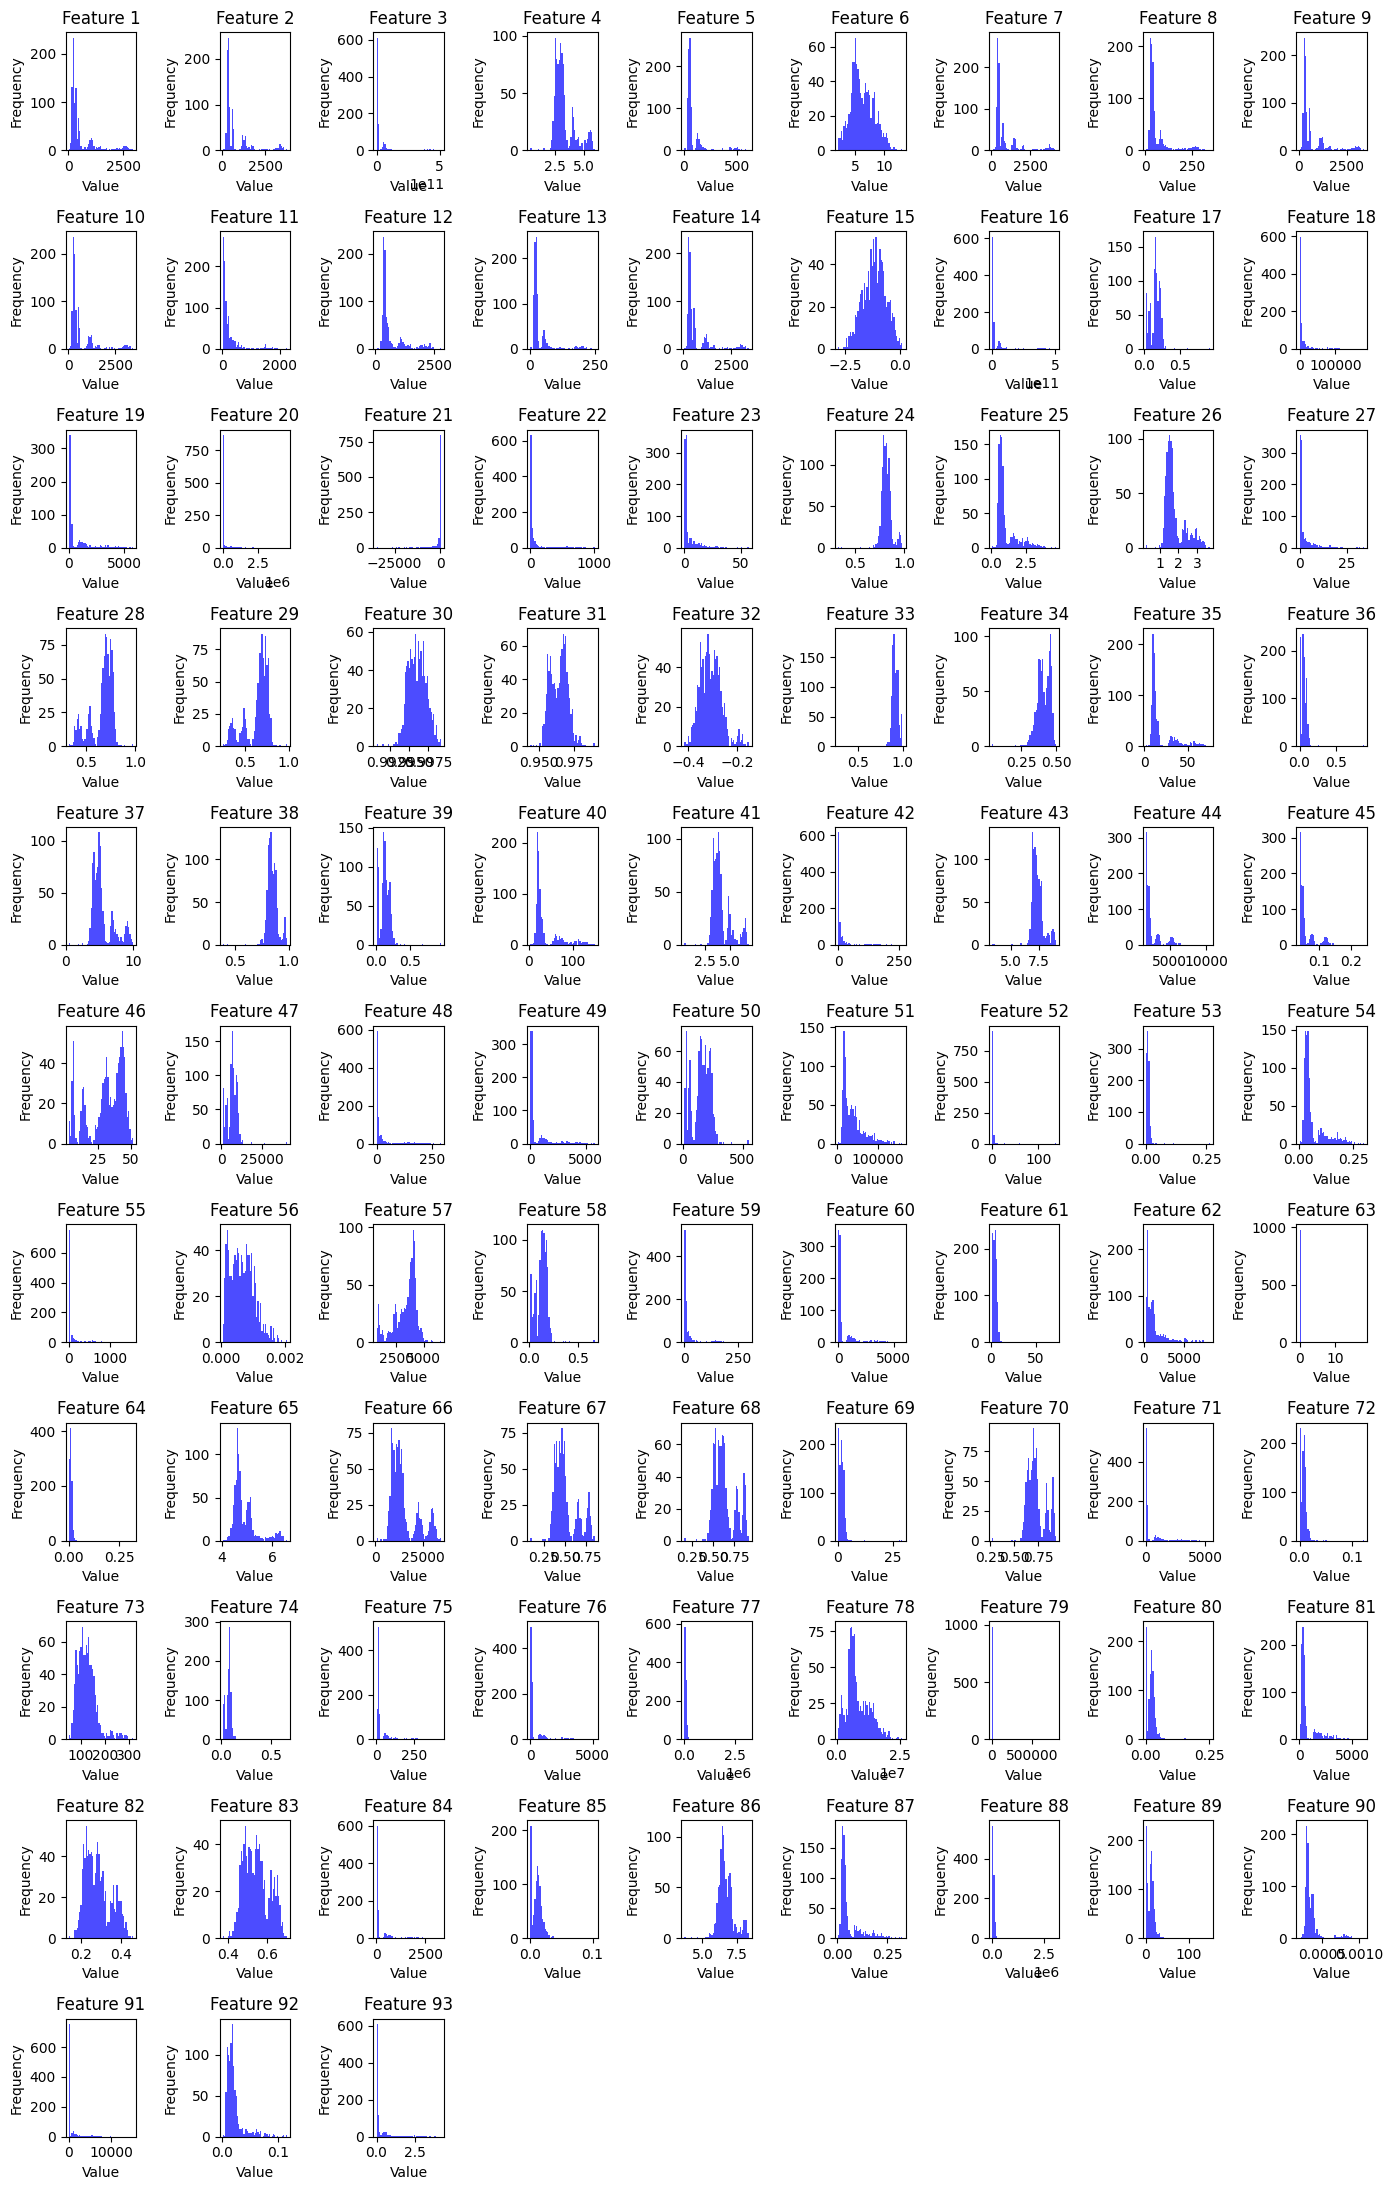

In [ ]:

# Convert the transformed training set to a DataFrame
X_train_transformed_df = combined_df.drop(['class'], axis='columns')

# Number of rows and columns for the subplot grid
n_rows = int(np.ceil(X_train_transformed_df.shape[1] / 9))
n_cols = 9

# Create a figure and a grid of subplots
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, 2*n_rows))

# Flatten the array of axes
axes = axes.flatten()

# Remove extra subplots
for i in range(X_train_transformed_df.shape[1], n_rows*n_cols):
    fig.delaxes(axes[i])

# Plot the distribution of each feature
for i in range(X_train_transformed_df.shape[1]):
    axes[i].hist(X_train_transformed_df.iloc[:, i], bins=50, color='blue', alpha=0.7)
    axes[i].set_title(f'Feature {i+1}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Display the plot
plt.tight_layout()
plt.show()

### PCA plot Befor Feature Selection

Standardises the features and projects them onto the first two principal components, coloured by class (0 = Healthy, 1 = PD, from `LabelEncoder`'s alphabetical order). The two classes overlap heavily in this 2D projection, which the presentation describes as the data not being linearly separable.

/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_label.py:116: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


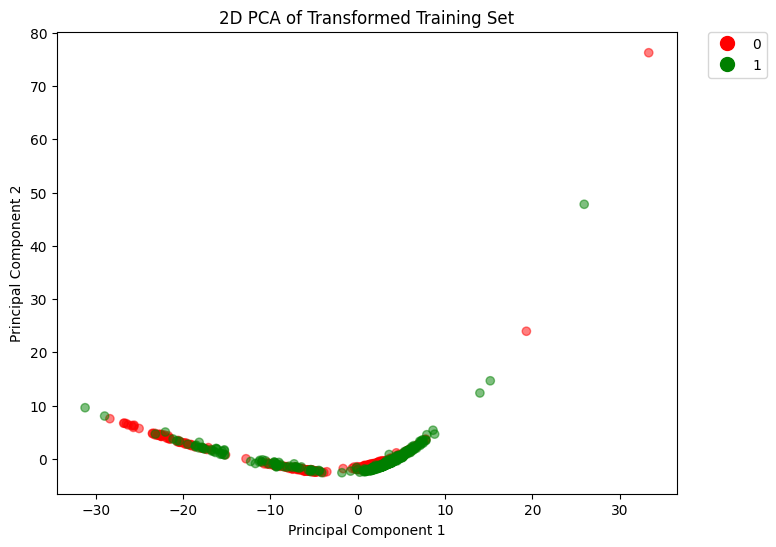

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Assuming that 'data' is your dataset and 'classes' is your target variable
# Standardize the features to have mean=0 and variance=1
scaler = StandardScaler()
data_scaled = scaler.fit_transform(combined_df.drop(['class'], axis='columns'))
lm = LabelEncoder()
y_un = lm.fit_transform(combined_df[['class']])
# Apply PCA and fit the scaled data. We are considering 2 principal components here.
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
X_train_transformed_pca_df = pd.DataFrame(data = data_pca, columns = ['Principal Component 1', 'Principal Component 2'])

colors = ['red', 'green', 'blue', 'purple', 'orange']  # Add more colors if you have more labels
unique_labels = np.unique(y_un)
label_colors = {label: colors[i] for i, label in enumerate(unique_labels)}

# Apply colors to each label
label_colors_array = [label_colors[label] for label in y_un]

# Plot the first two principal components with colors
plt.figure(figsize=(8,6))
plt.scatter(X_train_transformed_pca_df['Principal Component 1'], X_train_transformed_pca_df['Principal Component 2'], c=label_colors_array, alpha=0.5)
plt.title('2D PCA of Transformed Training Set')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Create a legend
patches = [plt.plot([],[], marker="o", ms=10, ls="", color=colors[i],
            label="{:d}".format(unique_labels[i]) )[0]  for i in range(len(unique_labels))]
plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0. )

plt.show()

A quick seaborn scatter coloured by class. The same feature is used on both axes, so the points fall on a diagonal line.

<Axes: xlabel='original_firstorder_10Percentile', ylabel='original_firstorder_10Percentile'>

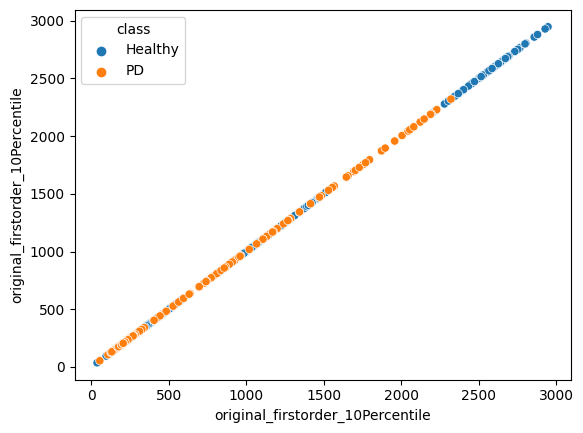

In [ ]:
sns.scatterplot(x='original_firstorder_10Percentile', y= "original_firstorder_10Percentile",hue='class', data=combined_df)

### Data quality checks

Column types, dataset shape, descriptive statistics and missing-value counts. The table has 984 samples, 93 numeric features and one class column, with **no missing values**.

In [ ]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 984 entries, 0 to 983
Data columns (total 94 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   original_firstorder_10Percentile                    984 non-null    float64
 1   original_firstorder_90Percentile                    984 non-null    float64
 2   original_firstorder_Energy                          984 non-null    float64
 3   original_firstorder_Entropy                         984 non-null    float64
 4   original_firstorder_InterquartileRange              984 non-null    float64
 5   original_firstorder_Kurtosis                        984 non-null    float64
 6   original_firstorder_Maximum                         984 non-null    float64
 7   original_firstorder_MeanAbsoluteDeviation           984 non-null    float64
 8   original_firstorder_Mean                            984 non-null    float64
 9  

In [ ]:
# dataset dimensions
print(combined_df.shape, '\n')

# generate descriptive statistics
combined_df.describe()

(984, 94) 



,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
count,984.000000,984.000000,9.840000e+02,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,...,984.000000,984.000000,984.000000,984.000000,9.840000e+02,984.000000,984.000000,984.000000,984.000000,984.000000
mean,595.225039,782.092859,4.427731e+10,3.265561,98.304546,6.221642,926.907513,62.409041,688.209101,695.986141,...,292.273258,0.011351,6.679263,0.057961,6.558797e+04,11.091800,0.000350,760.385224,0.021502,0.343722
std,631.323978,808.254649,9.855836e+10,0.906756,109.732986,1.988914,898.701626,61.384177,722.007417,730.226808,...,535.777199,0.008794,0.565227,0.055669,1.313355e+05,10.851585,0.000124,1702.483932,0.017099,0.693799
min,36.273463,46.924928,7.681624e+07,0.299290,5.041021,1.981784,57.423954,3.718441,41.438202,42.111298,...,3.745775,0.000342,3.689050,0.003139,8.791324e+01,0.140556,0.000192,0.145091,0.000413,0.001941
25%,229.459354,339.816640,3.648335e+09,2.651437,45.586525,4.793973,432.410118,30.664458,283.159614,287.493401,...,46.060012,0.005497,6.347924,0.025501,2.314554e+04,4.096219,0.000289,53.539110,0.011358,0.040105
50%,330.146082,415.644064,6.038820e+09,2.994435,58.534180,5.943987,493.512741,38.731536,368.350745,372.467041,...,60.005140,0.011214,6.559485,0.034453,5.177943e+04,11.102943,0.000309,77.821034,0.016929,0.058929
75%,545.676834,674.892178,1.623509e+10,3.444630,75.602448,7.598941,931.701904,59.715655,604.840018,613.177383,...,100.402183,0.015423,6.948737,0.056098,8.547041e+04,15.404069,0.000363,222.205916,0.022778,0.178941
max,2947.854688,3775.926367,5.106270e+11,5.976730,604.553833,13.170434,4156.120117,345.693134,3393.941941,3435.276611,...,3297.265480,0.103385,8.316049,0.327669,3.065657e+06,149.818187,0.001062,15094.398133,0.116805,4.137123


In [ ]:
#Find number of null values in each column

combined_df.isnull().sum()

original_firstorder_10Percentile          0
original_firstorder_90Percentile          0
original_firstorder_Energy                0
original_firstorder_Entropy               0
original_firstorder_InterquartileRange    0
                                         ..
original_ngtdm_Coarseness                 0
original_ngtdm_Complexity                 0
original_ngtdm_Contrast                   0
original_ngtdm_Strength                   0
class                                     0
Length: 94, dtype: int64

One-hot encodes `class` into `class_Healthy` and `class_PD`, which the first experiment uses as a two-column target.

In [ ]:
# One-hot encode the target class
encoded_df = pd.get_dummies(combined_df, columns = ['class'])

In [ ]:
encoded_df

,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,...,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,class_Healthy,class_PD
0,376.887061,452.657440,7.499335e+09,2.443337,41.880981,8.155804,526.283569,26.093703,411.481429,412.686615,...,6.596338,0.019473,127652.396900,12.715806,0.000300,49.789569,0.007001,0.054479,1,0
1,1339.955005,1698.769214,1.018852e+11,4.673930,179.628418,8.274374,1947.021729,128.708883,1510.702707,1535.422241,...,7.418840,0.132191,3131.502729,0.626596,0.000477,1918.919030,0.043260,0.982518,1,0
2,1253.228711,1580.040015,8.812310e+10,4.474478,146.946594,7.385406,1926.095703,108.017265,1406.950834,1415.240479,...,7.347031,0.120681,3739.132905,0.743288,0.000460,1534.265011,0.028468,0.832774,1,0
3,1486.487622,1798.005322,1.186344e+11,4.464402,159.791077,7.437434,2087.609131,107.400024,1635.806742,1649.023315,...,7.445861,0.117587,3605.620072,0.634974,0.000464,1779.288526,0.024351,1.024094,1,0
4,1385.145386,1721.686230,1.060276e+11,4.561917,177.360474,6.714416,2055.322998,115.274058,1544.794837,1555.364014,...,7.412145,0.128415,3060.015851,0.713496,0.000431,1978.431800,0.030537,0.897012,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
979,215.987637,298.094232,2.916217e+09,2.570572,43.237473,6.836284,358.943420,28.393895,254.540933,257.462311,...,6.521143,0.022294,98040.627258,14.625057,0.000299,48.424025,0.010698,0.044207,0,1
980,204.399155,289.623108,2.699150e+09,2.620092,44.391235,6.705623,360.825623,29.365939,244.410765,247.118408,...,6.587073,0.019837,106463.088533,14.750508,0.000311,45.887870,0.011258,0.042212,0,1
981,216.536041,304.772791,2.988618e+09,2.633910,48.510704,6.511942,362.526886,29.991923,257.614268,260.268158,...,6.516774,0.022726,84704.331322,14.209157,0.000311,49.453540,0.011269,0.045056,0,1
982,205.928458,284.663666,2.641044e+09,2.451400,44.625366,3.849628,358.422272,26.145309,242.874999,242.016479,...,6.328102,0.015492,153660.147580,22.208172,0.000312,29.680810,0.008969,0.026890,0,1


### Feature correlation

Shows a full annotated correlation matrix and a hierarchically clustered heatmap. Many radiomic features are strongly correlated with one another. The report uses this to motivate the feature-selection step later on.

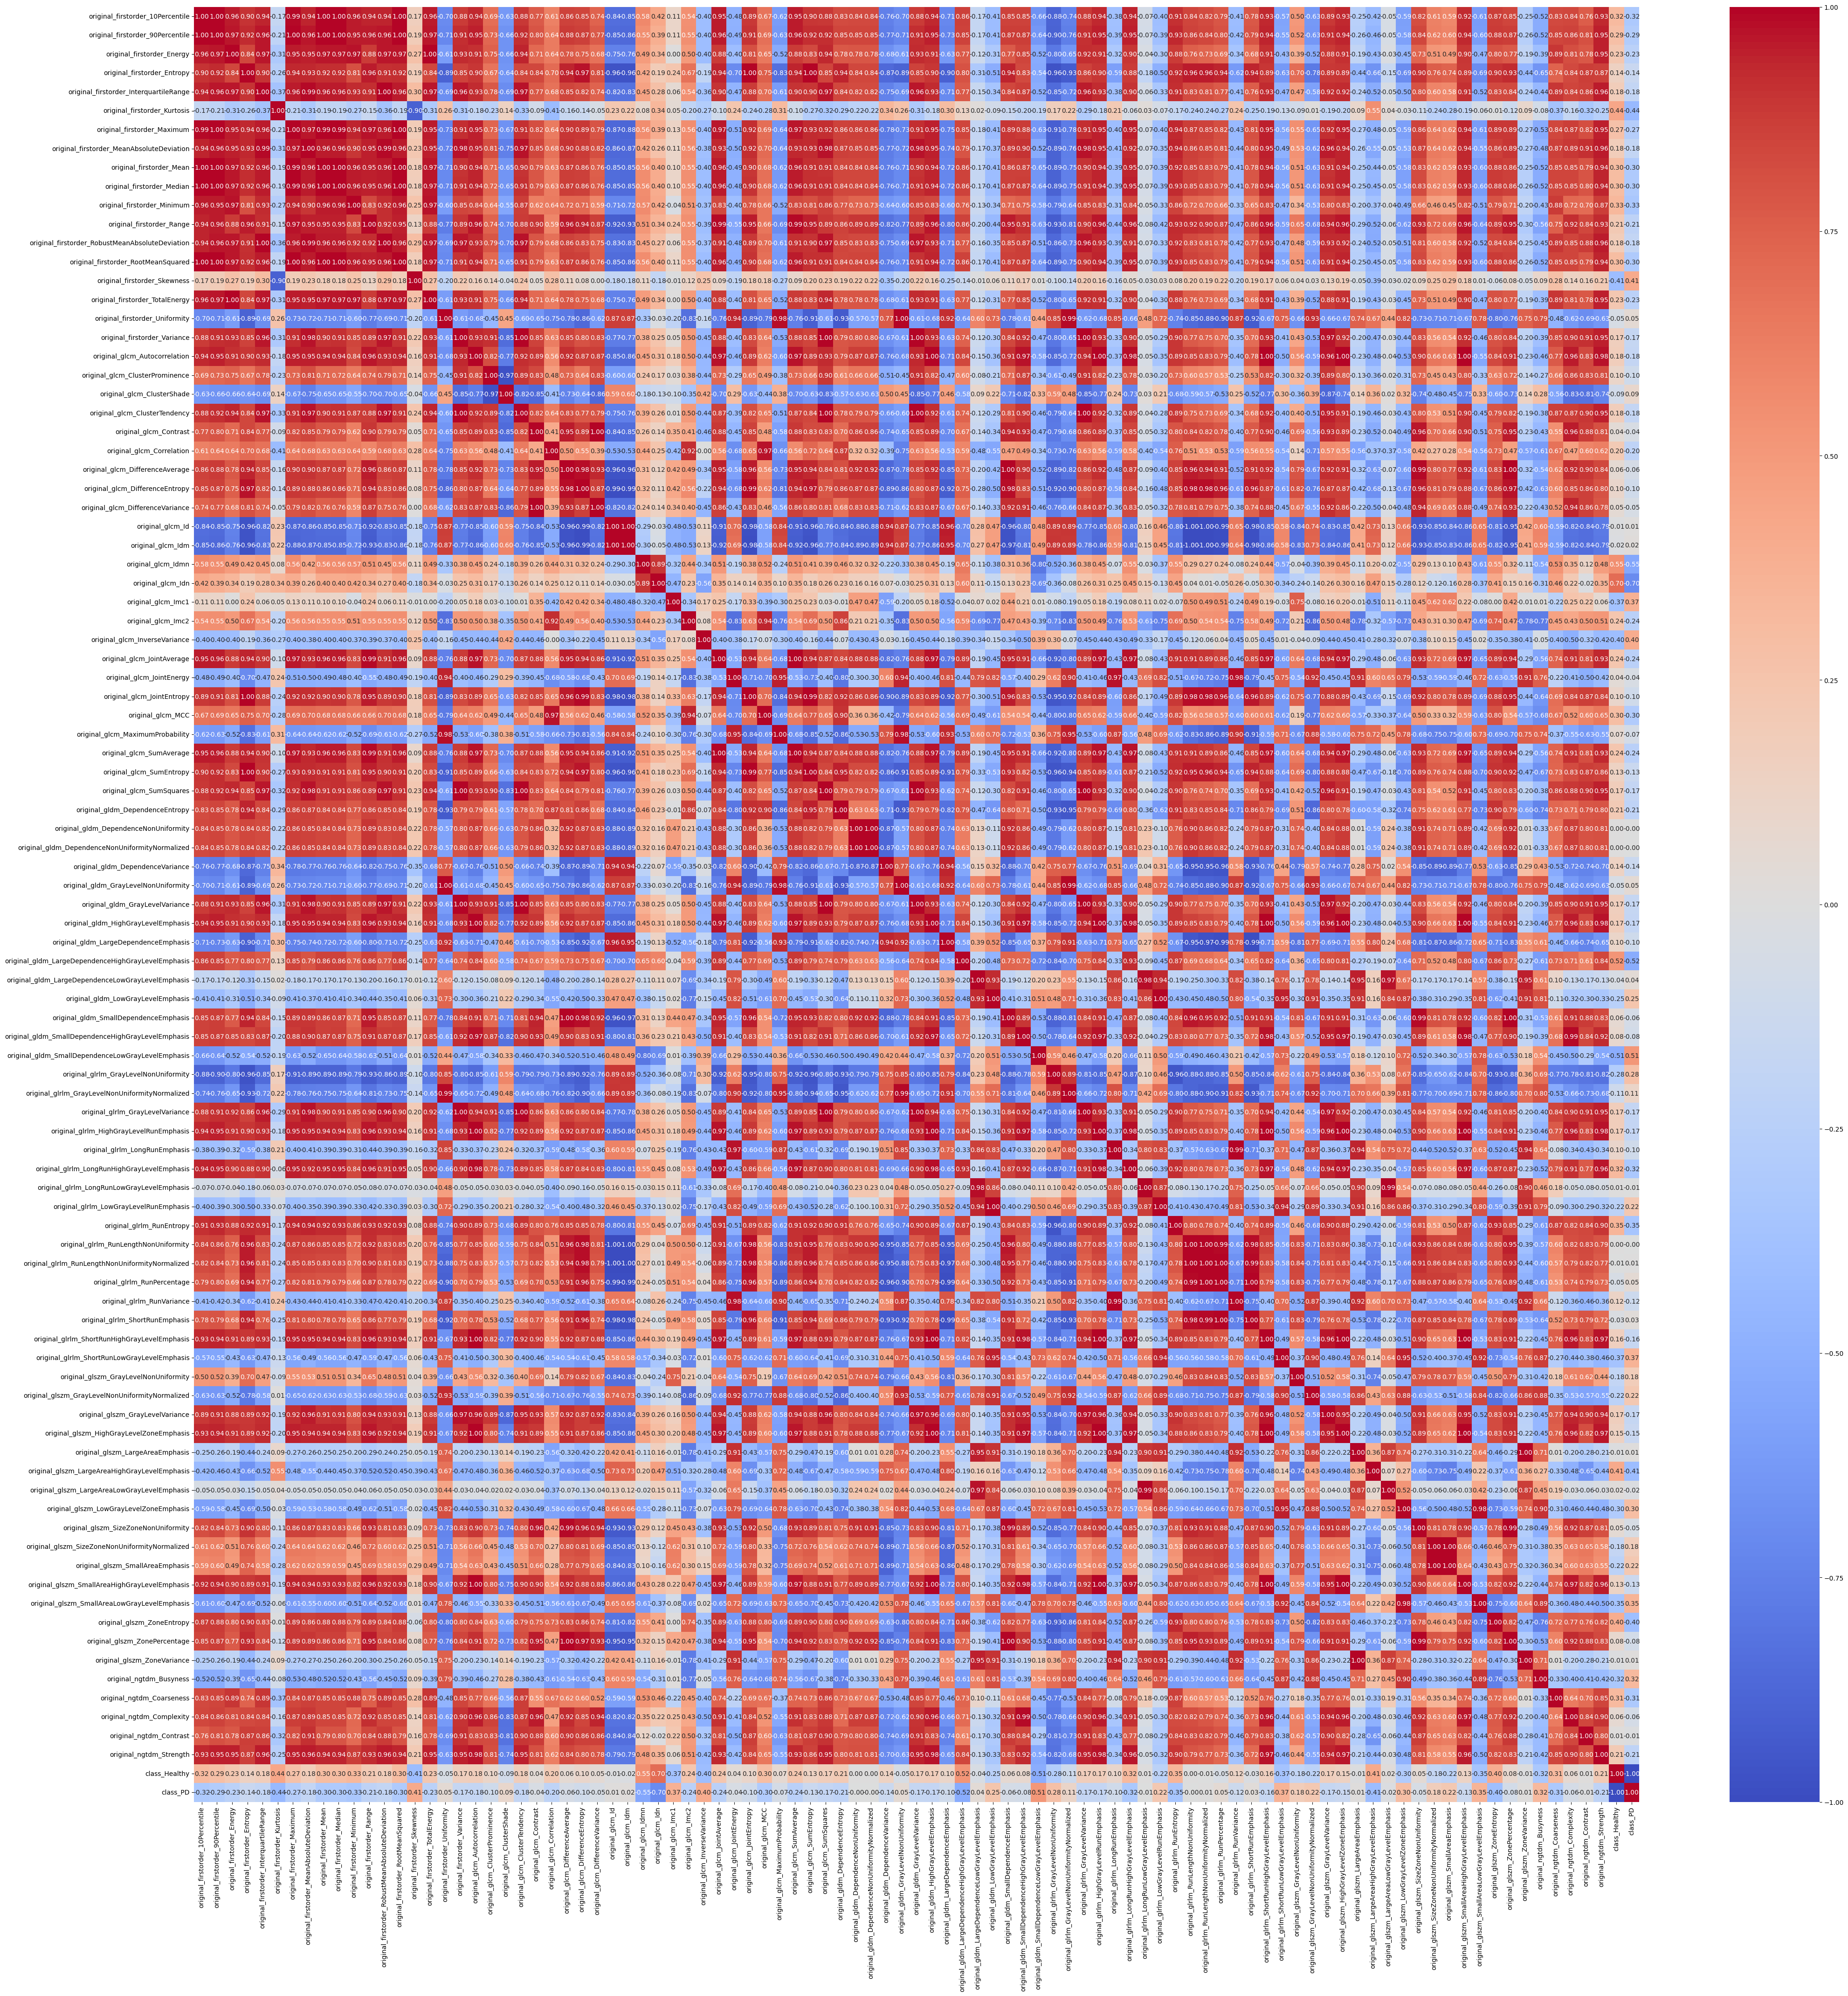

In [ ]:
plt.figure(figsize=(50, 50))
dataplot = sns.heatmap(encoded_df.corr(), annot=True, fmt='.2f', cmap="coolwarm")
#plt.savefig('/content/drive/MyDrive/ML_proj/co_relation_matrix.png', dpi=90)
plt.show()

<ipython-input-36-af51f5c4996a>:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  pp = sns.clustermap(combined_df.corr(), cmap="mako", linewidths=.5, figsize=(13,13))


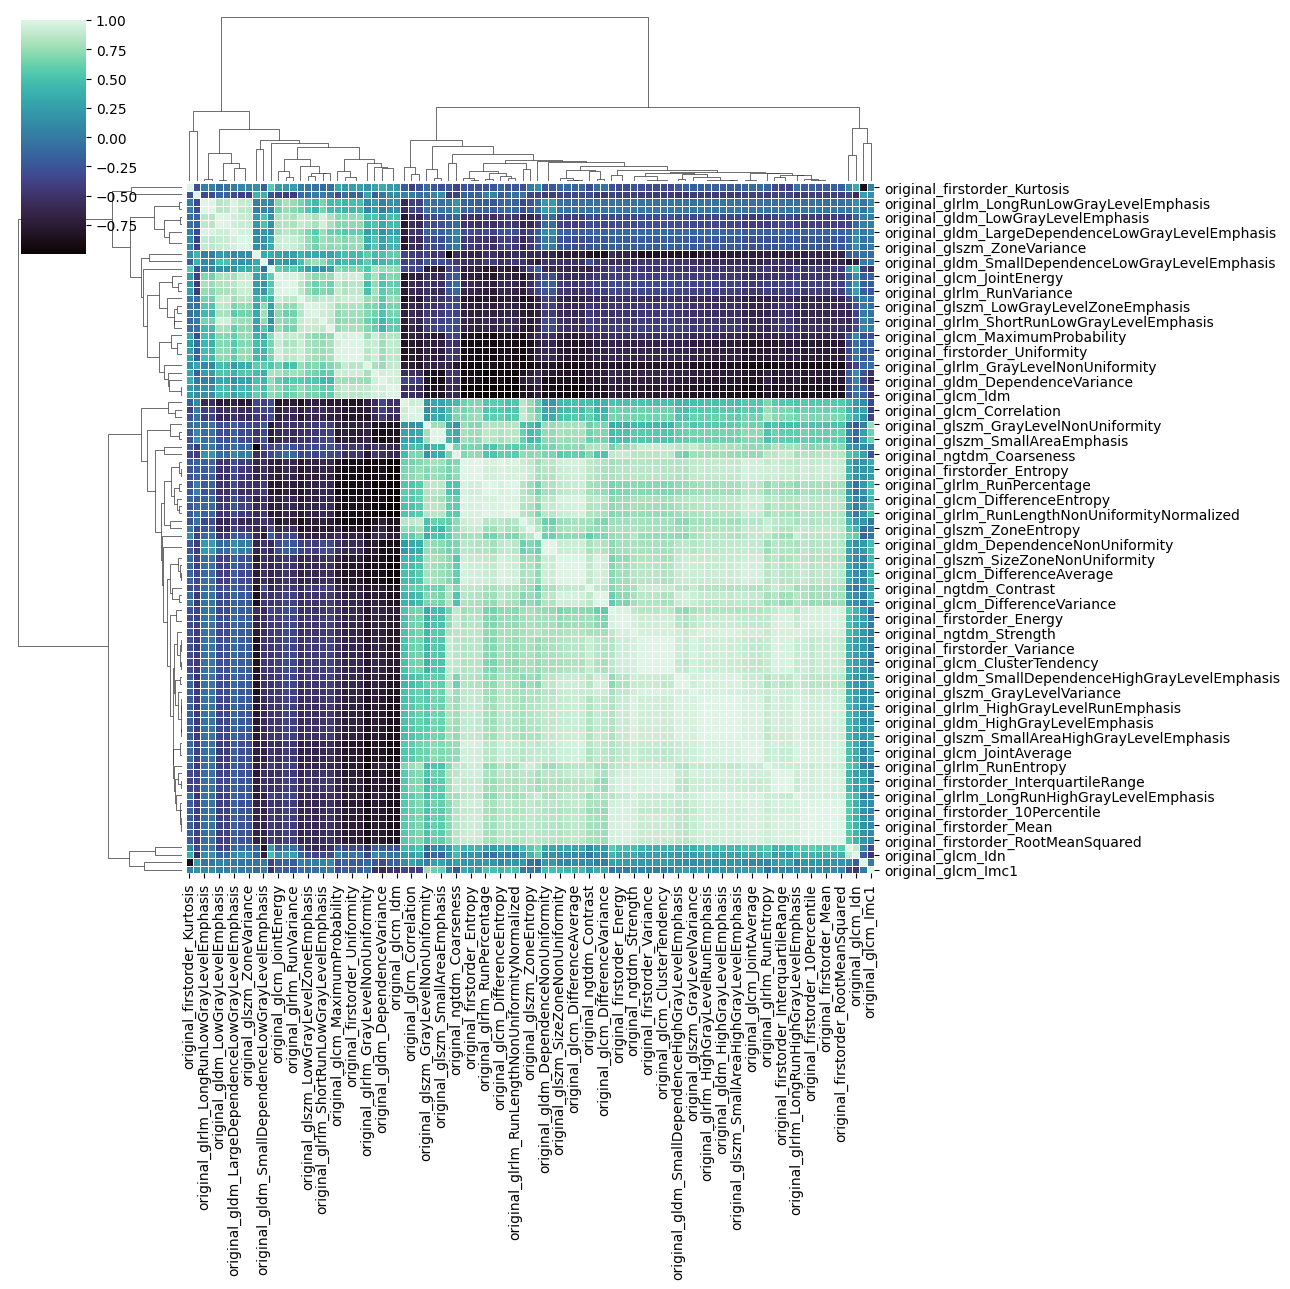

In [ ]:
pp = sns.clustermap(combined_df.corr(), cmap="mako", linewidths=.5, figsize=(13,13))
_ = plt.setp(pp.ax_heatmap.get_yticklabels(), rotation=0)

plt.show()

Shuffles the rows and separates the 93 features (`X`) from the one-hot labels (`y`).

> Note: as written, this cell samples `combined_df`, which has no `class_*` columns, yet the next cell drops them. The recorded outputs (985 rows) therefore come from a different notebook state, most likely with `encoded_df`.

In [ ]:
# Shuffle the rows
shuffled_encoded_df = combined_df.sample(frac=1, random_state=0).reset_index(drop=True)

In [ ]:
minmax = MinMaxScaler()
X = shuffled_encoded_df.drop(['class_Healthy', 'class_PD'] ,axis='columns')
y = shuffled_encoded_df[['class_Healthy', 'class_PD']]

In [ ]:
X

,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,222.018207,358.756268,3.996298e+09,3.109839,53.544113,5.396483,478.476044,42.650677,295.217232,303.115967,...,60.462917,0.014633,6.680730,0.034782,50637.844711,10.964188,0.000305,91.069418,0.020456,0.056842
1,183.326584,541.966650,6.570966e+09,3.494449,322.049187,1.207498,669.450195,149.063340,353.888301,321.419128,...,48.058810,0.007665,7.349758,0.038695,41141.833680,6.223406,0.000510,115.497847,0.072003,0.188971
2,229.484030,328.128528,3.451068e+09,2.818535,53.636032,5.272364,411.543640,34.029956,276.457266,279.420319,...,40.858822,0.026107,6.354534,0.032371,62067.074725,17.489642,0.000301,50.657203,0.016468,0.032918
3,98.671576,418.448175,3.839029e+09,3.251484,292.468540,1.196272,471.375214,132.174360,261.326921,307.421906,...,30.754550,0.022369,7.162671,0.020656,94514.068421,10.606755,0.000494,56.127488,0.090977,0.103335
4,287.339301,599.196777,1.210109e+10,3.362745,76.114029,4.384755,684.618164,85.512021,512.030096,557.199585,...,59.689297,0.006511,7.432671,0.036511,29624.513021,3.980398,0.000464,113.466045,0.038203,0.184460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
980,194.182404,535.104956,8.219329e+09,3.341401,289.787468,1.695447,614.786560,126.260365,409.435654,485.280090,...,45.449732,0.012490,7.093002,0.040037,32171.432980,5.981424,0.000500,82.739146,0.072770,0.135431
981,102.821172,424.910596,4.566090e+09,3.361446,285.175491,1.502591,470.190491,121.743719,294.024207,360.990356,...,39.779776,0.009042,7.132007,0.035556,45731.344000,7.609405,0.000501,68.122229,0.081852,0.105556
982,1268.490527,1527.158105,8.583099e+10,4.216443,127.689026,10.874973,1746.059448,94.792635,1389.850055,1410.198853,...,707.991109,0.001592,7.190758,0.114584,4677.164423,0.882211,0.000369,1554.234352,0.030552,0.770263
983,94.838785,404.689496,2.922320e+09,2.866617,273.182365,1.275498,442.727692,130.166912,219.399827,115.631172,...,24.681566,0.031281,7.135592,0.016288,150743.982044,16.740419,0.000403,47.962509,0.087684,0.105915


In [ ]:
y

,class_Healthy,class_PD
0,0,1
1,1,0
2,0,1
3,1,0
4,1,0
...,...,...
980,1,0
981,1,0
982,0,1
983,1,0


# Train Test Split

**Experiment 1 (90/10 split).** Holds out 10 % of the data as a test set (886 train / 99 test) and fits a Min-Max scaler on the training data only.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.10, random_state=42)
X_train = minmax.fit_transform(X_train)
X_test = minmax.transform(X_test)
print(len(X_train))
print(len(X_test))

886
99


In [ ]:
y_train

,class_Healthy,class_PD
615,1,0
887,1,0
792,1,0
254,0,1
909,1,0
...,...,...
106,1,0
270,1,0
860,0,1
435,1,0


In [ ]:
y_test

,class_Healthy,class_PD
613,1,0
451,1,0
731,0,1
436,1,0
275,1,0
...,...,...
878,1,0
558,1,0
533,1,0
668,1,0


# Model Training And Evaluation

Trains a default Random Forest (100 trees) on the two-column one-hot target. It's first scored with regression metrics (MSE 0.0101, R² 0.9577), then predictions are turned into classes with `argmax` for a confusion matrix and classification report.

**Recorded result (99 test samples):** accuracy 0.99. Healthy: precision 1.00, recall 0.98. PD: precision 0.97, recall 1.00.

> This early experiment doesn't appear in the report or slides. The "base model" reported there is Experiment 2 below, which uses a separate validation set.

In [ ]:
yte_arr = y_test.values
ytr_arr = y_train.values

In [ ]:
# Random Forest
model = RandomForestClassifier()
model.fit(X_train, ytr_arr)
#prediction
pred = model.predict(X_test)

mse = mean_squared_error(yte_arr, pred)
r2 = r2_score(yte_arr, pred)

print("Random Forest:")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R-squared: {r2:.4f}\n")

Random Forest:
Mean Squared Error: 0.0101
R-squared: 0.9577



In [ ]:
# Number of class vlaues in y_test
y_test.value_counts()

class_Healthy  class_PD
1              0           60
0              1           39
dtype: int64

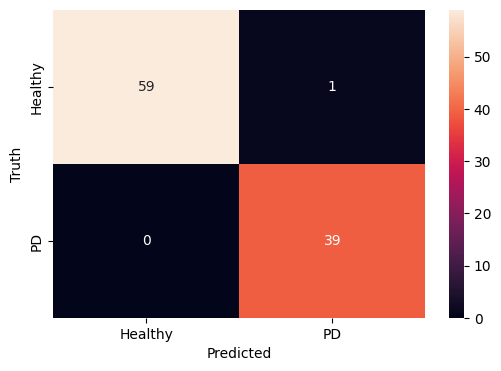

In [ ]:
# Confusion Matrix

class_names = ('Healthy', 'PD')

y_te = yte_arr.argmax(axis=1)
rf_pr = pred.argmax(axis=1)
cnf_matrix = metrics.confusion_matrix(y_te, rf_pr)

plt.figure(figsize=(6, 4))
sns.heatmap(cnf_matrix, annot=True, xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted')
plt.ylabel('Truth')

plt.show()

In [ ]:
# Classification Report

print(metrics.classification_report(y_te, rf_pr, target_names=class_names))

              precision    recall  f1-score   support

     Healthy       1.00      0.98      0.99        60
          PD       0.97      1.00      0.99        39

    accuracy                           0.99        99
   macro avg       0.99      0.99      0.99        99
weighted avg       0.99      0.99      0.99        99



# ***PROGRESS***


> Train, Validation and Test Split of the data

> Previous Model tunning using validation data

1.   Training And Validating the model
2.   Plotting Training Curves
3.   Testing on test data
4.   Confusion Matrix and report



> Updated Model with reduced features

1.   Training And Validating the model
2.   Plotting Training Curves
3.   Testing on test data
4.   Confusion Matrix and report







### Experiment 2: train / validation / test split

Re-shuffles the data (seed 42) and splits it **70 / 15 / 15** into 688 training, 148 validation and 148 test samples. The features are standardised with a `StandardScaler` fitted on the training set; the variable is named `scalar`, and a commented-out block shows the splits were once pickled to Drive. Labels are encoded with `LabelEncoder` (Healthy = 0, PD = 1).

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
shuffled_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

In [ ]:
train_data, val_data, test_data = np.split(shuffled_df, [int(.7*len(shuffled_df)), int(.85*len(shuffled_df))])
print(f"Size of Train set: {len(train_data)} \nSize of Valid set: {len(val_data)} \nSize of Test set: {len(test_data)}")

Size of Train set: 688 
Size of Valid set: 148 
Size of Test set: 148


In [ ]:
import pickle
from sklearn.preprocessing import StandardScaler, LabelEncoder
scalar = StandardScaler()
X_train = train_data.drop(['class'], axis='columns')
y_train = train_data[['class']]

X_val = val_data.drop(['class'], axis='columns')
y_val = val_data[['class']]

X_test= test_data.drop(['class'], axis='columns')
y_test = test_data[['class']]
"""
# Save the classification model
with open('/content/drive/MyDrive/ML_proj/Data/X_train.pkl', 'wb') as model_file:
    pickle.dump(X_train, model_file)

# Save the feature_selection model
with open('/content/drive/MyDrive/ML_proj/Data/X_val.pkl', 'wb') as model_file:
    pickle.dump(X_val, model_file)

with open('/content/drive/MyDrive/ML_proj/Data/X_test.pkl', 'wb') as model_file:
    pickle.dump(X_test, model_file)

# Save the classification model
with open('/content/drive/MyDrive/ML_proj/Data/y_train.pkl', 'wb') as model_file:
    pickle.dump(y_train, model_file)

# Save the feature_selection model
with open('/content/drive/MyDrive/ML_proj/Data/y_val.pkl', 'wb') as model_file:
    pickle.dump(y_val, model_file)

with open('/content/drive/MyDrive/ML_proj/Data/y_test.pkl', 'wb') as model_file:
    pickle.dump(y_test, model_file)
"""
X_train = scalar.fit_transform(X_train)
X_val = scalar.transform(X_val)
X_test = scalar.transform(X_test)

In [ ]:
y_train

,class
0,PD
1,Healthy
2,PD
3,Healthy
4,Healthy
...,...
683,PD
684,PD
685,PD
686,Healthy


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
le = LabelEncoder()

# Fit the encoder and transform the labels
y_train = le.fit_transform(y_train)
y_val = le.transform(y_val)
y_test = le.transform(y_test)

In [ ]:
y_test

array([0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0])

## ***Previous Model with validation split***

**Base model: Random Forest on all 93 features.** To get training curves from a non-iterative model, the forest is refit 20 times with 1, 2, …, 20 trees. Each "epoch" is one extra tree. Error (MSE on 0/1 labels, which equals the misclassification rate) and accuracy are recorded on the training and validation sets.

Training accuracy reaches 1.0 and validation accuracy ends at 0.9459 with 20 trees. The printed epoch counter is off by one (it shows 2 to 21).

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

# Random Forest
model = RandomForestClassifier(n_estimators=1, warm_start=False, random_state=42)

# Number of epochs
epochs = 20
train_loss = []
valid_loss = []
train_acc = []
valid_acc = []
for epoch in range(epochs):
    # Train the model
    model.n_estimators = epoch+1
    model.fit(X_train, y_train)

    # Make predictions on the training set and calculate metrics
    pred_train = model.predict(X_train)
    mse_train = mean_squared_error(y_train, pred_train)
    train_accuracy = model.score(X_train, y_train)

    # Make predictions on the validation set and calculate metrics
    pred_val = model.predict(X_val)
    mse_val = mean_squared_error(y_val, pred_val)
    val_accuracy = model.score(X_val, y_val)


    train_loss.append([mse_train])
    valid_loss.append([mse_val])
    train_acc.append([train_accuracy])
    valid_acc.append([val_accuracy])

    # Print metrics
    print(f"Epoch: {epoch+2}/{epochs}")
    print(f"Train - Mean Squared Error: {mse_train:.4f}, Accuracy: {train_accuracy:.4f}")
    print(f"Validation - Mean Squared Error: {mse_val:.4f}, Accuracy: {val_accuracy:.4f}\n")


Epoch: 2/20
Train - Mean Squared Error: 0.0174, Accuracy: 0.9826
Validation - Mean Squared Error: 0.0811, Accuracy: 0.9189

Epoch: 3/20
Train - Mean Squared Error: 0.0247, Accuracy: 0.9753
Validation - Mean Squared Error: 0.0743, Accuracy: 0.9257

Epoch: 4/20
Train - Mean Squared Error: 0.0044, Accuracy: 0.9956
Validation - Mean Squared Error: 0.0473, Accuracy: 0.9527

Epoch: 5/20
Train - Mean Squared Error: 0.0102, Accuracy: 0.9898
Validation - Mean Squared Error: 0.0608, Accuracy: 0.9392

Epoch: 6/20
Train - Mean Squared Error: 0.0044, Accuracy: 0.9956
Validation - Mean Squared Error: 0.0473, Accuracy: 0.9527

Epoch: 7/20
Train - Mean Squared Error: 0.0073, Accuracy: 0.9927
Validation - Mean Squared Error: 0.0541, Accuracy: 0.9459

Epoch: 8/20
Train - Mean Squared Error: 0.0058, Accuracy: 0.9942
Validation - Mean Squared Error: 0.0405, Accuracy: 0.9595

Epoch: 9/20
Train - Mean Squared Error: 0.0058, Accuracy: 0.9942
Validation - Mean Squared Error: 0.0541, Accuracy: 0.9459

Epoch: 1

### ***Accuracy & Loss Curves***

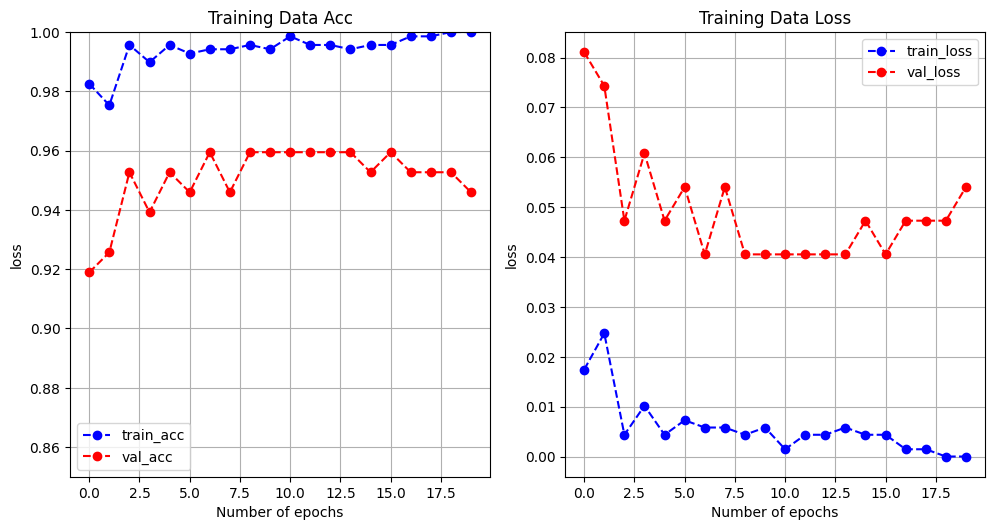

In [ ]:
training_loss = np.array(train_loss)
validation_loss = np.array(valid_loss)

train_accuracy = np.array(train_acc)
validation_accuracy = np.array(valid_acc)


fig = plt.figure(figsize=(15,10))

plt.subplot(231)
plt.plot(train_accuracy, 'bo--', label='train_acc')
plt.plot(validation_accuracy , 'ro--', label = 'val_acc')
plt.title('Training Data Acc')
plt.xlabel('Number of epochs')
plt.ylabel('loss')
plt.grid()
plt.legend()
plt.ylim(0.85, 1)
plt.tight_layout()

plt.subplot(232)
plt.plot(training_loss, 'bo--', label='train_loss')
plt.plot(validation_loss, 'ro--', label = 'val_loss')
plt.title('Training Data Loss')
plt.xlabel('Number of epochs')
plt.ylabel('loss')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

Evaluates the final 20-tree base model on the held-out **test** set; the print statement says "Validation" but the data is the test set. **Test accuracy: 0.9189.**

The confusion matrix and classification report follow (Healthy precision 0.91 / recall 0.95, PD precision 0.93 / recall 0.87, accuracy 0.92). This is the "Random Forest" row of the comparison table in the report.

In [ ]:
pred_test = model.predict(X_test)
mse_test = mean_squared_error(y_test, pred_test)
acc_test = model.score(X_test, y_test)

print(f"Validation - Mean Squared Error: {mse_test:.4f}, Accuracy: {acc_test:.4f}\n")


Validation - Mean Squared Error: 0.0811, Accuracy: 0.9189



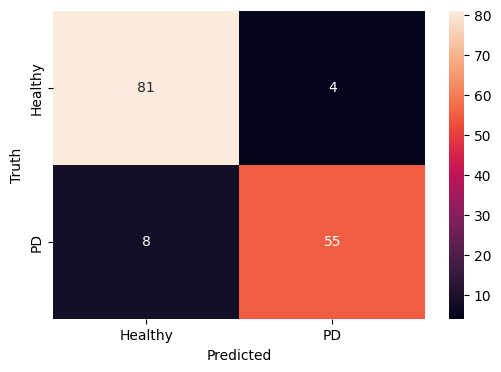

In [ ]:
# Confusion Matrix

class_names = ('Healthy', 'PD')

cnf_matrix = metrics.confusion_matrix(y_test, pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(cnf_matrix, annot=True, xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted')
plt.ylabel('Truth')

plt.show()

In [ ]:
# Classification Report

print(metrics.classification_report(y_test, pred_test, target_names=class_names))

              precision    recall  f1-score   support

     Healthy       0.91      0.95      0.93        85
          PD       0.93      0.87      0.90        63

    accuracy                           0.92       148
   macro avg       0.92      0.91      0.92       148
weighted avg       0.92      0.92      0.92       148



### ***ROC Curve***

ROC curve for the PD class using the forest's predicted probabilities. The recorded plot shows **AUC = 0.98**.

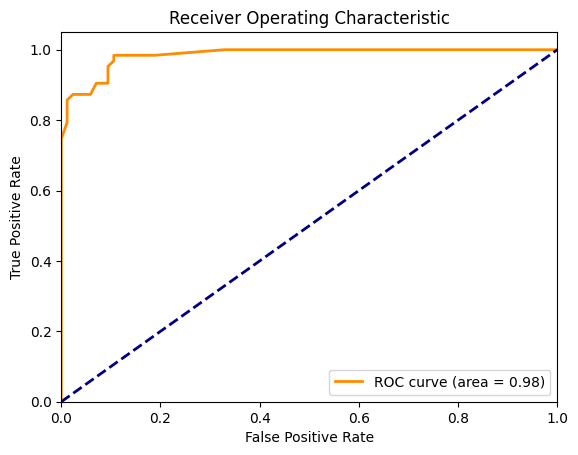

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

n_classes = 2
# Get the probabilities of your predictions
y_score = model.predict_proba(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot the ROC curve
plt.figure()
plt.plot(fpr[1], tpr[1], color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc[1])
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


## Navive Bayes Model

Gaussian Naive Bayes on the same 93 standardised features, as a simple probabilistic baseline. **Test accuracy: 0.547.** The classification report below gives accuracy 0.55 and macro F1 0.53. NB assumes features are independent, and these features are strongly correlated, which likely contributes to the poor result.

In [ ]:
from sklearn.naive_bayes import GaussianNB
clf = GaussianNB()

# Train the classifier
clf.fit(X_train, y_train)

clf.score(X_test, y_test)

0.5472972972972973

In [ ]:
pred_test = clf.predict(X_test)

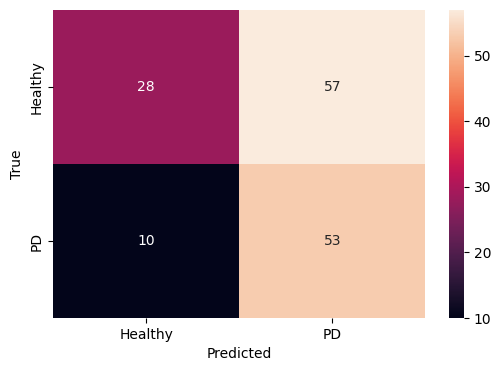

In [ ]:
# Confusion Matrix

class_names = ('Healthy', 'PD')

cnf_matrix = metrics.confusion_matrix(y_test, pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(cnf_matrix, annot=True, xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

In [ ]:
# Classification Report

print(metrics.classification_report(y_test, pred_test, target_names=class_names))

              precision    recall  f1-score   support

     Healthy       0.74      0.33      0.46        85
          PD       0.48      0.84      0.61        63

    accuracy                           0.55       148
   macro avg       0.61      0.59      0.53       148
weighted avg       0.63      0.55      0.52       148



## ***Updated Model with Features Selection***

**Improved model: SVM-based feature selection followed by a Random Forest.**

- `SelectFromModel(LinearSVC(penalty="l2", max_iter=20))` fits a linear SVM on the training set and keeps the features whose absolute coefficient is at least the mean, reducing the input from **93 to 39 features**. This removes much of the redundancy seen in the correlation matrix.
- A Random Forest is grown from 1 to 20 trees on the selected features, as in the base model.
- The "loss" is scikit-learn's `log_loss` computed on hard class predictions rather than probabilities, so it tracks the error rate instead of a calibrated probabilistic loss.

Validation accuracy reaches **0.9595** with 20 trees.

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss

# Create the feature selection and classifier objects
feature_selection = SelectFromModel(LinearSVC(dual=False, penalty="l2", max_iter=20, random_state=42))
classification = RandomForestClassifier(n_estimators=1, warm_start=False, random_state=42)

# Apply feature selection on training and validation sets
X_train_transformed = feature_selection.fit_transform(X_train, y_train)
X_val_transformed = feature_selection.transform(X_val)


# Lists to store scores and losses
train_scores = []
val_scores = []
train_losses = []
val_losses = []

# Number of iterations
n_iters = 20

for i in range(n_iters):
    # Train the classifier
    classification.n_estimators = i+1
    classification.fit(X_train_transformed, y_train)

    # Calculate training and validation scores
    train_score = classification.score(X_train_transformed, y_train)
    val_score = classification.score(X_val_transformed, y_val)

    # Calculate training and validation losses
    train_loss = log_loss(y_train, classification.predict(X_train_transformed))
    val_loss = log_loss(y_val, classification.predict(X_val_transformed))

    # Save scores and losses
    train_scores.append(train_score)
    val_scores.append(val_score)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Print scores and losses every 20 iterations
    if i % 2 == 0:
        print(f"Iteration {i}:")
        print(f"Training score: {train_score}, Validation score: {val_score}")
        print(f"Training loss: {train_loss}, Validation loss: {val_loss}")


Iteration 0:
Training score: 0.9796511627906976, Validation score: 0.9459459459459459
Training loss: 0.7334464352436633, Validation loss: 1.9483055886009273
Iteration 2:
Training score: 0.9956395348837209, Validation score: 0.9527027027027027
Training loss: 0.15716709326649944, Validation loss: 1.7047673900258113
Iteration 4:
Training score: 0.9956395348837209, Validation score: 0.9527027027027027
Training loss: 0.1571670932664994, Validation loss: 1.7047673900258113
Iteration 6:
Training score: 0.9956395348837209, Validation score: 0.9662162162162162
Training loss: 0.1571670932664994, Validation loss: 1.2176909928755797
Iteration 8:
Training score: 1.0, Validation score: 0.9594594594594594
Training loss: 2.2204460492503136e-16, Validation loss: 1.4612291914506954
Iteration 10:
Training score: 0.997093023255814, Validation score: 0.9527027027027027
Training loss: 0.10477806217766635, Validation loss: 1.7047673900258113
Iteration 12:
Training score: 0.9941860465116279, Validation score:

In [ ]:
print(f"Shape of X_train with all features: {X_train.shape} \nShape of X_train after features reduction: {X_train_transformed.shape}")

Shape of X_train with all features: (688, 93) 
Shape of X_train after features reduction: (688, 39)


***Plotting loss curves***

Displays the fitted feature selector and the final classifier configuration (20 trees).

In [ ]:
feature_selection

SelectFromModel(estimator=LinearSVC(dual=False, max_iter=20, random_state=42))

In [ ]:
classification

RandomForestClassifier(n_estimators=20, random_state=42)

### ***Accuracy & Loss Curves***

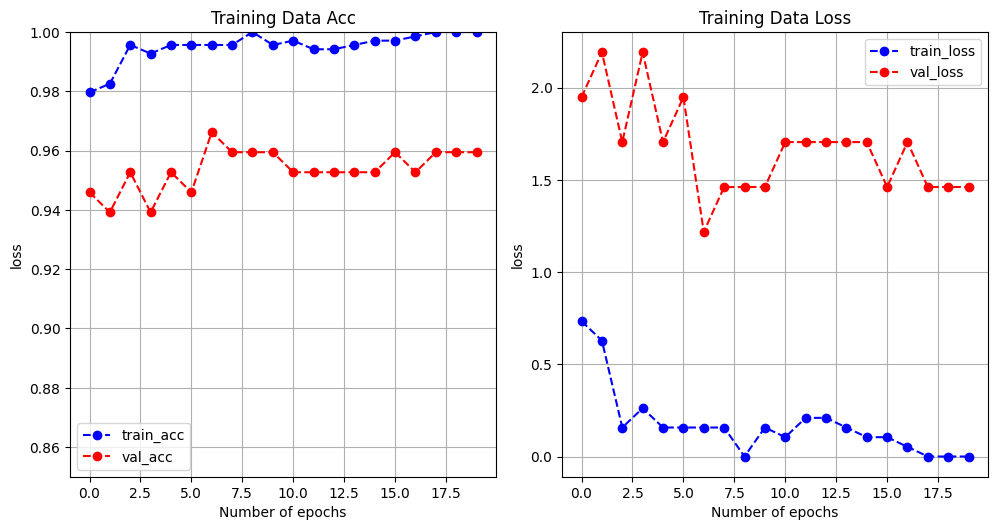

In [ ]:
train_loss_arr = np.array(train_losses)
val_loss_arr = np.array(val_losses)

train_accuracy = np.array(train_scores)
validation_accuracy = np.array(val_scores)

fig = plt.figure(figsize=(15,10))

plt.subplot(231)
plt.plot(train_accuracy, 'bo--', label='train_acc')
plt.plot(validation_accuracy , 'ro--', label = 'val_acc')
plt.title('Training Data Acc')
plt.xlabel('Number of epochs')
plt.ylabel('loss')
plt.grid()
plt.legend()
plt.ylim(0.85, 1)
plt.tight_layout()

plt.subplot(232)
plt.plot(train_loss_arr, 'bo--', label='train_loss')
plt.plot(val_loss_arr, 'ro--', label = 'val_loss')
plt.title('Training Data Loss')
plt.xlabel('Number of epochs')
plt.ylabel('loss')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

Evaluates the improved model on the held-out **test** set; the print again says "Validation". **Test accuracy: 0.9595.**

In [ ]:
X_test_transformed = feature_selection.transform(X_test)


In [ ]:
pred_test = classification.predict(X_test_transformed)
mse_test = mean_squared_error(y_test, pred_test)
acc_test = classification.score(X_test_transformed, y_test)

print(f"Validation - Mean Squared Error: {mse_test:.4f}, accuracy: {acc_test:.4f}\n")


Validation - Mean Squared Error: 0.0405, accuracy: 0.9595



In [ ]:
class_names = ('Healthy', 'PD')

### ***Confusion Matrix***

Confusion matrix of the improved model on the test set: 84 of 85 healthy and 58 of 63 PD scans are classified correctly. The classification report below (accuracy 0.96, macro F1 0.96) is Table 3 of the report.

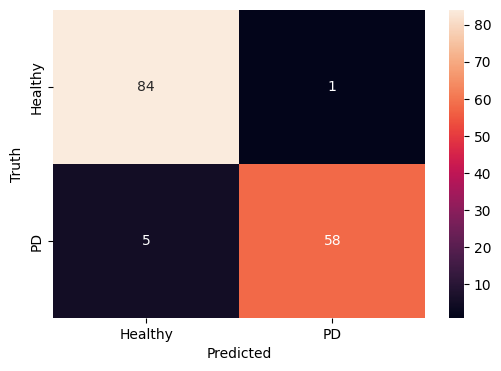

In [ ]:
#
cnf_matrix = metrics.confusion_matrix(y_test, pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(cnf_matrix, annot=True, xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted')
plt.ylabel('Truth')

plt.show()

In [ ]:
# Classification Report

print(metrics.classification_report(y_test, pred_test, target_names=class_names))

              precision    recall  f1-score   support

     Healthy       0.94      0.99      0.97        85
          PD       0.98      0.92      0.95        63

    accuracy                           0.96       148
   macro avg       0.96      0.95      0.96       148
weighted avg       0.96      0.96      0.96       148



## Navive Bayes Model Reduced

Gaussian Naive Bayes on the 39 selected features.

> Note: the score cell compares predictions on the **validation** features with the **test** labels (`clf.score(X_val_transformed, y_test)`), so the printed 0.473 isn't a valid metric. The classification report further down is computed on the test set (accuracy 0.55) and is the meaningful result.

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss

# Create the feature selection and classifier objects
feature_selection = SelectFromModel(LinearSVC(dual=False, penalty="l2", max_iter=20, random_state=42))
X_train_transformed = feature_selection.fit_transform(X_train, y_train)
X_val_transformed = feature_selection.transform(X_val)


In [ ]:
from sklearn.naive_bayes import GaussianNB
clf = GaussianNB()

# Train the classifier
clf.fit(X_train_transformed, y_train)

clf.score(X_val_transformed, y_test)

0.47297297297297297

In [ ]:
X_test_transformed = feature_selection.transform(X_test)

In [ ]:
pred_test = clf.predict(X_test_transformed)

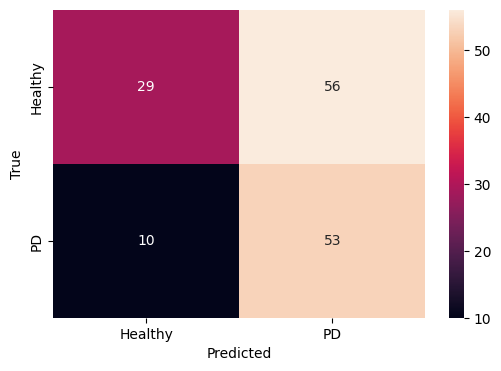

In [ ]:
# Confusion Matrix

class_names = ('Healthy', 'PD')

cnf_matrix = metrics.confusion_matrix(y_test, pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(cnf_matrix, annot=True, xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

In [ ]:
# Classification Report

print(metrics.classification_report(y_test, pred_test, target_names=class_names))

              precision    recall  f1-score   support

     Healthy       0.74      0.34      0.47        85
          PD       0.49      0.84      0.62        63

    accuracy                           0.55       148
   macro avg       0.61      0.59      0.54       148
weighted avg       0.63      0.55      0.53       148



Saving models

Pickles the improved Random Forest, the feature selector and the `StandardScaler` to Google Drive. The scaler is saved as `Minmax_transform2.pkl` even though it's a StandardScaler.

> Note: the web app in `app/models/` loads differently named files (`classification_model.pkl`, `feature_selection_model.pkl`, `scalar.pkl`). Its classifier has 10 trees and 41 input features, so it comes from a different training run than the 20-tree, 39-feature model trained here.

In [ ]:
import pickle

In [ ]:
!mkdir "/content/drive/MyDrive/ML_proj/Trained_Models2"

In [ ]:
# Save the classification model
with open('/content/drive/MyDrive/ML_proj/Trained_Models2/classification_model2.pkl', 'wb') as model_file:
    pickle.dump(classification, model_file)

# Save the feature_selection model
with open('/content/drive/MyDrive/ML_proj/Trained_Models2/feature_selection_model2.pkl', 'wb') as model_file:
    pickle.dump(feature_selection, model_file)

with open('/content/drive/MyDrive/ML_proj/Trained_Models2/Minmax_transform2.pkl', 'wb') as model_file:
    pickle.dump(scalar, model_file)

### ***ROC Curve***

ROC curve of the improved model on the test set. The recorded plot shows **AUC = 0.98**.

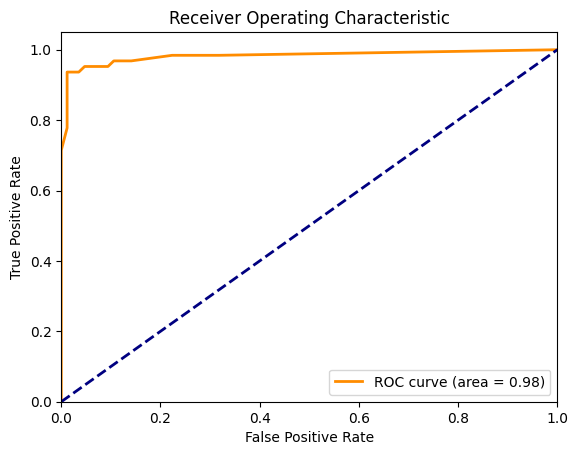

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

n_classes = 2
# Get the probabilities of your predictions
y_score = classification.predict_proba(X_test_transformed)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot the ROC curve
plt.figure()
plt.plot(fpr[1], tpr[1], color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc[1])
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


Histograms of the 39 selected (standardised) training features.

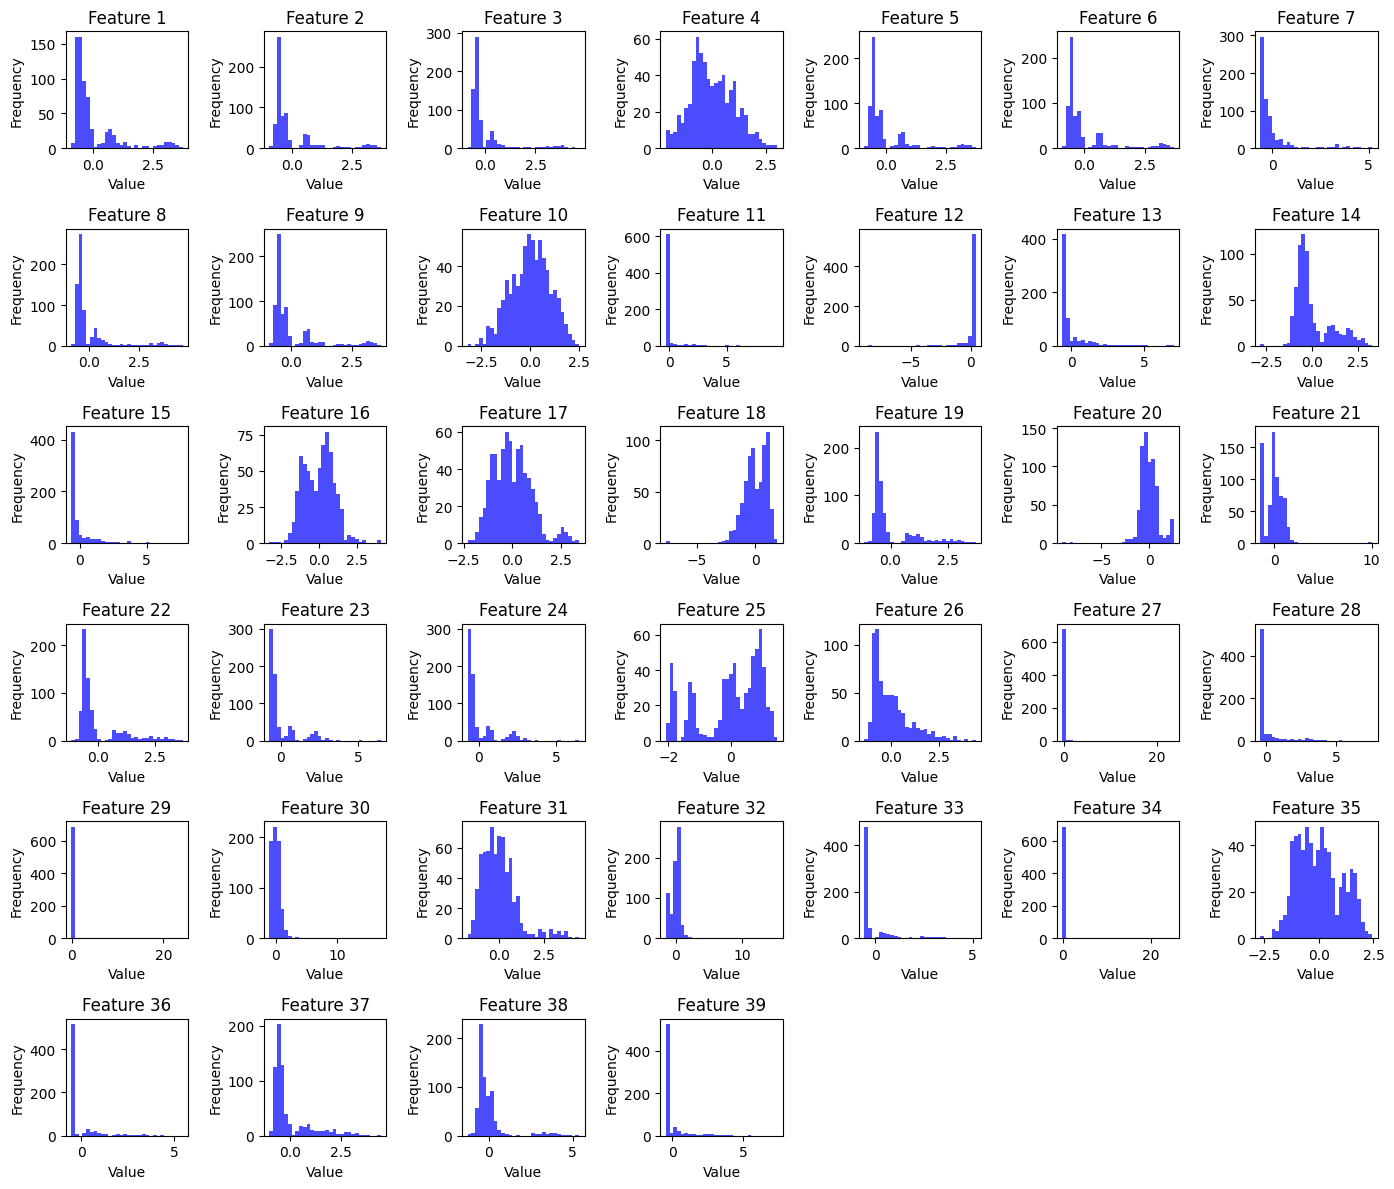

In [ ]:

# Convert the transformed training set to a DataFrame
X_train_transformed_df = pd.DataFrame(X_train_transformed)

# Number of rows and columns for the subplot grid
n_rows = int(np.ceil(X_train_transformed_df.shape[1] / 7))
n_cols = 7

# Create a figure and a grid of subplots
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, 2*n_rows))

# Flatten the array of axes
axes = axes.flatten()

# Remove extra subplots
for i in range(X_train_transformed_df.shape[1], n_rows*n_cols):
    fig.delaxes(axes[i])

# Plot the distribution of each feature
for i in range(X_train_transformed_df.shape[1]):
    axes[i].hist(X_train_transformed_df.iloc[:, i], bins=30, color='blue', alpha=0.7)
    axes[i].set_title(f'Feature {i+1}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Display the plot
plt.tight_layout()
plt.show()

### PCA plot After Feature Selection

PCA of the 39 selected training features. The classes still overlap in two dimensions, so the forest's accuracy relies on non-linear combinations of features rather than a simple linear split.

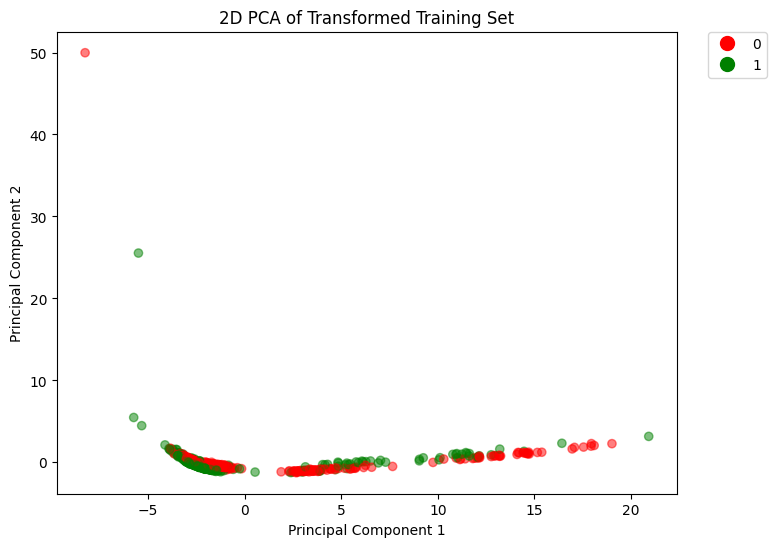

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Apply PCA
pca = PCA(n_components=2)
X_train_transformed_df = pd.DataFrame(X_train_transformed)
X_train_transformed_pca = pca.fit_transform(X_train_transformed_df)

# Convert to DataFrame
X_train_transformed_pca_df = pd.DataFrame(data = X_train_transformed_pca, columns = ['Principal Component 1', 'Principal Component 2'])

colors = ['red', 'green', 'blue', 'purple', 'orange']  # Add more colors if you have more labels
unique_labels = np.unique(y_train)
label_colors = {label: colors[i] for i, label in enumerate(unique_labels)}

# Apply colors to each label
label_colors_array = [label_colors[label] for label in y_train]

# Plot the first two principal components with colors
plt.figure(figsize=(8,6))
plt.scatter(X_train_transformed_pca_df['Principal Component 1'], X_train_transformed_pca_df['Principal Component 2'], c=label_colors_array, alpha=0.5)
plt.title('2D PCA of Transformed Training Set')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Create a legend
patches = [plt.plot([],[], marker="o", ms=10, ls="", color=colors[i],
            label="{:d}".format(unique_labels[i]) )[0]  for i in range(len(unique_labels))]
plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0. )

plt.show()


# ***Plotting_ROI***

A visual check of the pre-processing on one IXI subject: the PD25 subcortical labels and the PD25 brain template are overlaid on the scan **before** and **after** registration. After registration, the subject's anatomy lines up with the atlas structures, which is what makes a single atlas mask valid for every subject.

> The Drive folders `IXI_brain/female/` and `Sub_Data/Healthy/` used here aren't created in this notebook.

In [ ]:
import nibabel as nib
img1 = nib.load('/content/drive/MyDrive/ML_proj/IXI_brain/female/002-Guys-0828-T1.nii.gz')
img2 = nib.load('/content/drive/MyDrive/ML_proj/Sub_Data/Healthy/002-Guys-0828-T1.nii.gz')
#ref_skull = nib.load('/content/drive/MyDrive/ML_proj/MNUPD25/PD25-T1MPRAGE-template-1mm.nii.gz')
ref_brain = nib.load('/content/drive/MyDrive/ML_proj/MNUPD25/PD25-T1MPRAGE-brain-1mm.nii.gz')
mask_im = nib.load('/content/drive/MyDrive/ML_proj/MNUPD25/PD25-subcortical-1mm.nii.gz')

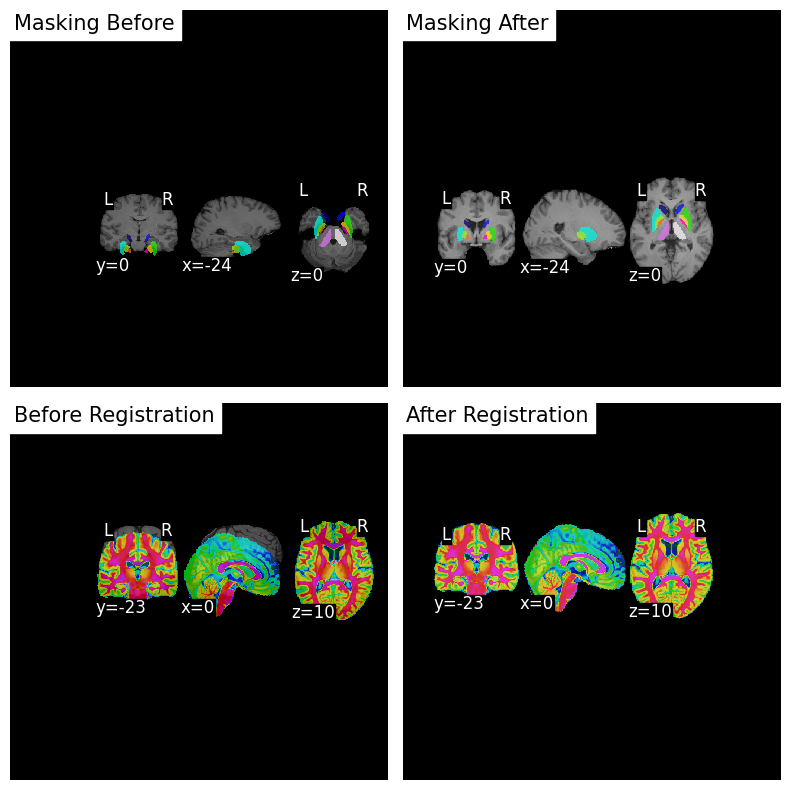

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(8, 8))

plotting.plot_roi(mask_im, img1, axes=axs[0, 0], title='Masking Before', draw_cross=False)

plotting.plot_roi(mask_im, img2, axes=axs[0, 1], title='Masking After', draw_cross=False)

plotting.plot_roi(ref_brain, img1, axes=axs[1, 0], title='Before Registration', draw_cross=False)


plotting.plot_roi(ref_brain, img2, axes=axs[1, 1], title='After Registration', draw_cross=False)


plt.tight_layout()
plt.show()


### Mask For Feature Extraction

The binary region-of-interest mask used for feature extraction and by the web app.

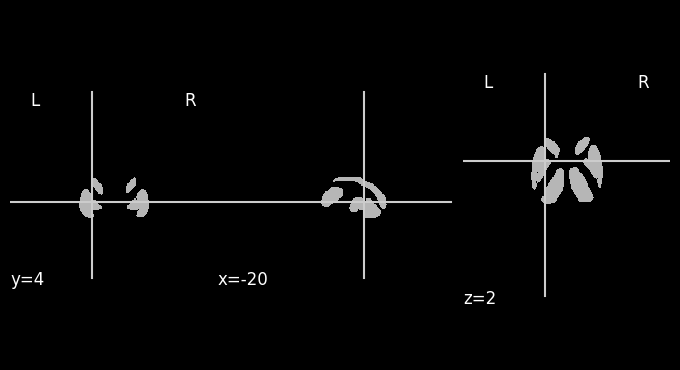

In [ ]:
img = nib.load('/content/drive/MyDrive/ML_proj/MNUPD25/PD25-subcortical-1mm_bmask.nii.gz')
plotting.plot_anat(img, cut_coords=(-20, 4, 2))

## Summary

| Model | Features | Test accuracy | Notes |
|---|---|---|---|
| Random Forest, 90/10 split (Experiment 1) | 93 | 0.99 (99 samples) | Early experiment, not in the report |
| Random Forest, base (Experiment 2) | 93 | 0.92 | ROC AUC 0.98 |
| Gaussian Naive Bayes | 93 | 0.55 | |
| Gaussian Naive Bayes | 39 | 0.55 | |
| **Random Forest + SVM feature selection** | **39** | **0.96** | ROC AUC 0.98; precision 0.96, recall 0.95, F1 0.96 (macro) |

- **Atlas-based pre-processing** (registration to PD25 and a subcortical mask) gives a compact, interpretable radiomic description of the regions most affected by Parkinson's disease.
- **Removing redundant, highly correlated features** with an L2 linear SVM cut the input from 93 to 39 features and raised test accuracy from 0.92 to 0.96.
- **Caveat:** all healthy scans come from IXI and all PD scans from PPMI, so the class label is fully confounded with the source dataset (scanner, site, protocol). The split is also random by scan, not by subject. The file names in the recorded output show that the PD scans come from about 217 distinct PPMI subjects, 89 of whom have more than one scan, so scans of the same person can land in both the training and test sets. Neither effect was analysed in this project, and both may inflate the reported accuracy.
- The trained pipeline is deployed as a local **Flask** web app (see `app/` and the README), which predicts the class of an uploaded NIfTI volume that has already been registered to the PD25 template.